# **Airbnb Prices and Guest Ratings in the City of Los Angeles**
BANA 212 | Team B4: Ashley Yang, Dhruv Sharma, Tina Tsai, Christine Lau



# **1. Project Introduction & Research Questions**

## 1.1 Project Background

Airbnb is a popular short-term rental platform that offers travelers a variety of accommodation options, ranging from private rooms to entire homes. In a competitive rental market such as Los Angeles, listing prices can vary considerably depending on property characteristics, available amenities, host attributes, and location.

Understanding the factors associated with Airbnb prices can provide useful insights for hosts making pricing decisions and travelers comparing accommodation options. Additionally, examining guest ratings may help identify which listing characteristics are associated with higher levels of guest satisfaction.



## 1.2 Project Objective

The primary objective of this project is to investigate the factors associated with Airbnb nightly listing prices in the City of Los Angeles. We focus on property characteristics, amenities, host-related attributes, and neighborhood to better understand differences in advertised prices across listings.

As a secondary objective, we examine how listing characteristics, amenities, and nightly prices are associated with guest ratings.

We use descriptive statistics, data visualizations, group comparisons, and multiple linear regression to explore these relationships.

## 1.3 Research Questions

### RQ1: Property Characteristics and Nightly Prices

How do property characteristics, including bedrooms, bathrooms, guest capacity, and room type, relate to Airbnb nightly prices in Los Angeles?

*Methods:* Pivot tables, descriptive statistics, ANOVA, and multiple regression. A neighborhood subsection compares median prices and evaluates the additional in-sample fit from neighborhood indicators.

### RQ2: Amenities and Nightly Prices

Are listings with certain amenities, including Wi-Fi, parking, pool/spa, air conditioning, kitchen, and washer/dryer, associated with higher nightly prices after accounting for other property characteristics?

*Methods:* Amenity grouping, pivot tables, visualizations, and multiple regression.

### RQ3: Host Characteristics and Nightly Prices

How are host characteristics, particularly Superhost status and availability, associated with nightly prices?

*Methods:* Group comparisons, descriptive statistics, and multiple regression.

### RQ4: Listing Characteristics and Guest Ratings

Are listing characteristics, amenities, and nightly prices associated with guest ratings?

*Methods:* Descriptive statistics, correlation analysis, and multiple regression with guest ratings as the outcome.

## 1.4 Dataset Overview

Our project uses an Airbnb listings dataset obtained from Inside Airbnb.

The original dataset contains 43,781 listings and 90 variables covering locations across Los Angeles County. Each row represents an individual Airbnb listing, while columns describe characteristics such as price, property type, room type, amenities, host information, and guest ratings.

Because our research focuses specifically on the City of Los Angeles, we will filter the dataset using the neighbourhood_group_cleansed variable before conducting the main analyses.



**Key variables include:**


*   Nightly price: Primary outcome for pricing analyses.
*   Property characteristics: Bedrooms, bathrooms, guest capacity, room type, and property type.
*   Amenities: Wi-Fi, parking, pool/spa, air conditioning, kitchen, and washer/dryer.
*   Host characteristics: Superhost status and listing availability.
*   Guest ratings: Secondary outcome measuring overall guest reviews.
*   Location: Neighborhood information used to understand geographic differences.


## 1.5 Analytical Approach

Our analysis follows five main stages:

1. Data Import and Exploration: Load the dataset, examine its structure, summarize key variables, and visualize distributions.

2. Data Cleaning and Feature Engineering: Filter listings to the City of Los Angeles, address missing values, prepare numerical variables, and create amenity indicators.

3. Research Question Analysis: Apply descriptive statistics, comparisons, and regression methods to address each research question.

4. Results and Interpretation: Interpret statistical findings and identify meaningful relationships between listing characteristics, prices, and guest ratings.

5. Conclusions and Limitations: Summarize the main insights, discuss limitations, and explain potential practical implications.

The project focuses on identifying statistical associations rather than establishing causal relationships.

# 2. Library Setup & Data Import

This section prepares the Python environment and imports the Airbnb listings dataset used throughout the project.

We begin by importing the necessary Python libraries for data manipulation, statistical analysis, and visualization. Next, we load the original dataset and verify that it was imported successfully.

The dataset will be explored in Section 3 before any cleaning or transformations are performed in Section 4.

## 2.1 Import Python Libraries

In [ ]:
# pandas: load, explore, clean, and manipulate datasets
import pandas as pd

# numpy: numerical operations and mathematical transformations
import numpy as np

# matplotlib: create and customize visualizations
import matplotlib.pyplot as plt

# seaborn: create statistical visualizations
import seaborn as sns

# statsmodels: build statistical regression models
import statsmodels.formula.api as smf

# scipy.stats: statistical tests
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["figure.dpi"] = 120

## 2.2 Load the Airbnb Dataset

The dataset was obtained from Inside Airbnb and contains listing-level information for properties located throughout Los Angeles County.

Each row represents one Airbnb listing, while each column describes a particular characteristic, such as nightly price, room type, property amenities, host information, or guest ratings.

We first load the original CSV file without modifying any variables. This allows us to examine the raw data before performing geographic filtering, data cleaning, and feature engineering.

- Data source: Inside Airbnb

- File format: CSV

- Unit of observation: One Airbnb listing per row

The dataset will be filtered to the City of Los Angeles during the data cleaning stage.

In [ ]:
from pathlib import Path

# Upload listings(4).csv or listings.csv using Colab's Files panel.
candidates = [
    directory / name
    for directory in (Path("/content"), Path.cwd())
    for name in ("listings.csv", "listings(4).csv")
]
file_path = next((path for path in candidates if path.is_file()), None)
if file_path is None:
    raise FileNotFoundError("Upload listings(4).csv or listings.csv in the Colab Files panel.")

df = pd.read_csv(file_path, low_memory=False)
df["price"] = pd.to_numeric(
    df["price"].astype("string").str.replace(r"[$,]", "", regex=True),
    errors="coerce",
).astype(float)
print(f"Loaded {file_path.name}: {len(df):,} listings and {df.shape[1]} columns.")

Loaded listings.csv: 43,781 listings and 90 columns.


## 2.3 Verify the Data Import

In [ ]:

# Verify dataset dimensions
print("Dataset shape:", df.shape)

# Check variables needed for the research questions
key_columns = [
    "id",
    "price",
    "bedrooms",
    "bathrooms_text",
    "accommodates",
    "room_type",
    "property_type",
    "amenities",
    "host_is_superhost",
    "availability_365",
    "review_scores_rating",
    "neighbourhood_cleansed",
    "neighbourhood_group_cleansed"
]

missing_columns = [
    col for col in key_columns
    if col not in df.columns
]

if not missing_columns:
    print("All key research variables are present.")
else:
    print("Missing columns:", missing_columns)

# Check whether each listing has a unique ID
print("Duplicate listing IDs:", df["id"].duplicated().sum())


Dataset shape: (43781, 90)
All key research variables are present.
Duplicate listing IDs: 0


# 3. Initial Data Exploration (EDA)

This section explores the original Airbnb listings dataset to understand its structure, geographic coverage, key variables, and data quality.

We use descriptive statistics and visualizations to identify patterns, missing values, and potential outliers that may influence our analyses.

All observations in this section refer to the original dataset unless otherwise specified. Data cleaning and preparation of the City of Los Angeles analysis dataset will be performed in Section 4.

## 3.1 Dataset Structure and Overview
We begin by examining the dataset dimensions, variable types, and sample observations. This provides an initial understanding of the information available for our research questions.

In [ ]:
# Display dataset dimensions
print(f"Number of listings: {df.shape[0]:,}")
print(f"Number of variables: {df.shape[1]}")

# Examine column names, non-null counts, and data types
df.info()

# Preview selected variables relevant to our research
preview_columns = [
    "id",
    "neighbourhood_cleansed",
    "neighbourhood_group_cleansed",
    "room_type",
    "accommodates",
    "bedrooms",
    "bathrooms_text",
    "price",
    "host_is_superhost",
    "review_scores_rating"
]

display(df[preview_columns].head())


Number of listings: 43,781
Number of variables: 90
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43781 entries, 0 to 43780
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            43781 non-null  int64  
 1   listing_url                                   43781 non-null  object 
 2   scrape_id                                     43781 non-null  int64  
 3   last_scraped                                  43781 non-null  int64  
 4   source                                        6274 non-null   object 
 5   name                                          43781 non-null  object 
 6   description                                   43541 non-null  object 
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   43779 non-null  object 
 9   host_id   

,id,neighbourhood_cleansed,neighbourhood_group_cleansed,room_type,accommodates,bedrooms,bathrooms_text,price,host_is_superhost,review_scores_rating
0,2708,Hollywood,City of Los Angeles,Private room,1,1.0,1 shared bath,76.31,t,4.87
1,2732,Santa Monica,Other Cities,Private room,1,1.0,1 private bath,215.21,f,4.41
2,6033,Woodland Hills,City of Los Angeles,Entire home/apt,3,1.0,1 bath,99.40,f,4.38
3,6931,Hollywood,City of Los Angeles,Private room,1,1.0,1 shared bath,69.50,t,4.87
4,152514,Manhattan Beach,Other Cities,Entire home/apt,2,1.0,1 bath,173.25,t,5.00


## 3.2 Geographic Coverage
The original dataset includes Airbnb listings across Los Angeles County, rather than exclusively within the City of Los Angeles.

Before conducting the main analyses, we examine how listings are distributed across the geographic groups identified in the dataset.

This distinction is important because our research questions focus specifically on Airbnb listings in the City of Los Angeles.

,Listings,Percentage
neighbourhood_group_cleansed,,
City of Los Angeles,21687,49.5
Other Cities,18007,41.1
Unincorporated Areas,4087,9.3


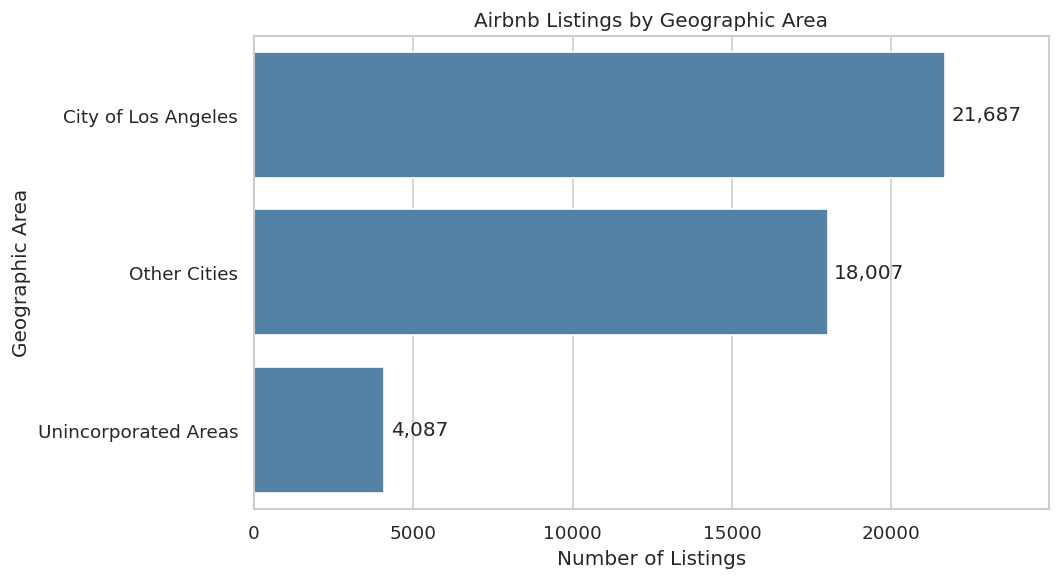

In [ ]:
# Count listings by geographic group
geo_counts = (
    df["neighbourhood_group_cleansed"]
    .value_counts()
)

# Display geographic distribution table
geo_summary = pd.DataFrame({
    "Listings": geo_counts,
    "Percentage": (geo_counts / len(df) * 100).round(1)
})

display(geo_summary)

# Visualize geographic distribution
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=geo_counts.values,
    y=geo_counts.index,
    color="steelblue"
)

# Add listing counts to each bar
for i, count in enumerate(geo_counts.values):
    ax.text(
        count + 200, i,
        f"{count:,}",
        va="center"
    )

plt.title("Airbnb Listings by Geographic Area")
plt.xlabel("Number of Listings")
plt.ylabel("Geographic Area")
plt.xlim(0, geo_counts.max() * 1.15)
plt.tight_layout()
plt.show()


**Initial Observation**

The dataset contains 43,781 listings, including 21,687 listings (49.5%) classified as City of Los Angeles. The remaining listings are located in other cities or unincorporated areas.

Because approximately half of the original observations fall outside our target geographic area, the dataset must be filtered before conducting the main research-question analyses.

We will perform this filtering in Section 4.

## 3.3 Missing Values and Data Quality
Missing data can affect both descriptive statistics and regression analyses. Variables with substantial missing values may require special consideration during data preparation.

We calculate the number and percentage of missing observations for each variable, then visualize the variables with the highest missing-value percentages.

At this stage, we only identify missing values. Decisions about how to handle them will be addressed in Section 4.

,Missing Count,Missing (%)
host_since,43781,100.00
neighborhood_overview,43781,100.00
host_thumbnail_url,43781,100.00
host_acceptance_rate,43781,100.00
host_response_rate,43781,100.00
host_response_time,43781,100.00
host_total_listings_count,43781,100.00
host_neighbourhood,43781,100.00
host_verifications,43781,100.00
neighbourhood,43781,100.00


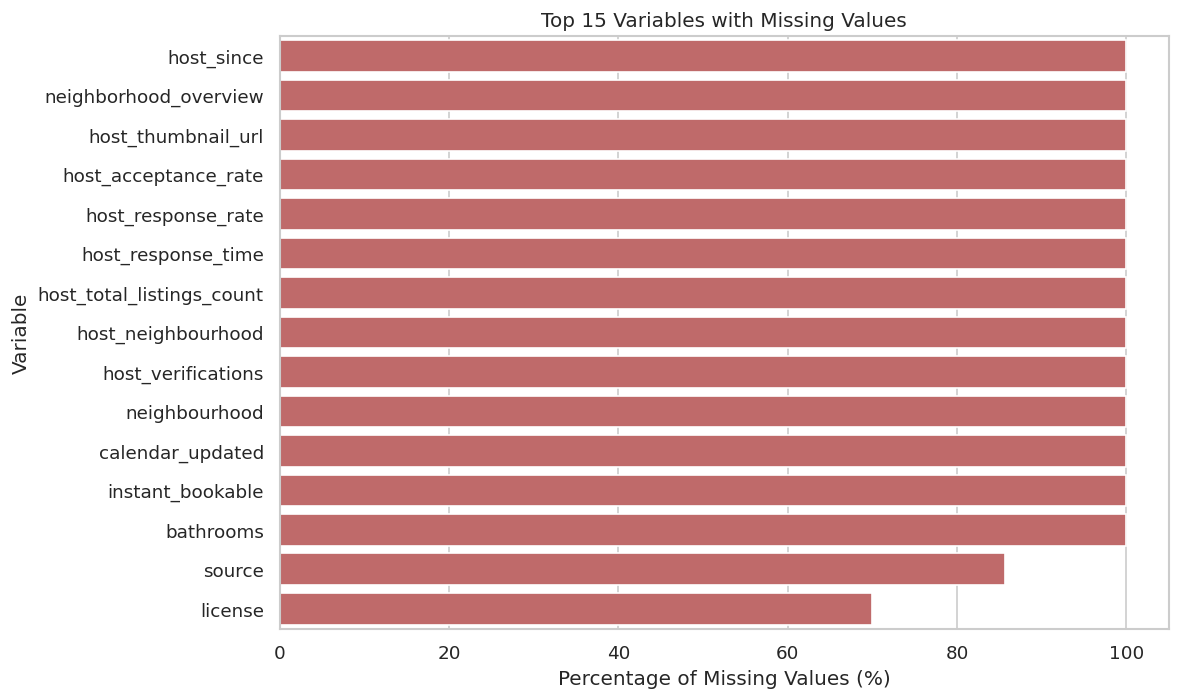

In [ ]:
# Calculate missing values for every column
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing (%)": df.isna().mean() * 100
})

# Keep columns containing missing values
missing_summary = (
    missing_summary[missing_summary["Missing Count"] > 0]
    .sort_values("Missing (%)", ascending=False)
)

# Display the missing-value table
display(missing_summary.round(2))

# Select the 15 columns with most missing data
top_missing = missing_summary.head(15)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=top_missing,
    x="Missing (%)",
    y=top_missing.index,
    color="indianred"
)

plt.title("Top 15 Variables with Missing Values")
plt.xlabel("Percentage of Missing Values (%)")
plt.ylabel("Variable")
plt.xlim(0, 105)
plt.tight_layout()
plt.show()


**Initial Observation**

Several variables contain missing values, including important variables used in our pricing and guest rating analyses.

In particular, the numeric bathrooms column contains no observations, whereas bathrooms_text is available for nearly all listings. This suggests that bathroom information may need to be extracted from the text column.

Additionally, nightly price is missing for approximately 16.2% of listings, while overall guest ratings are missing for approximately 24.8%.

These missing values will be considered when preparing the analysis datasets, with particular attention to maintaining consistency across regression models.

## 3.4 Descriptive Statistics

In [ ]:
# Select numerical variables relevant to our analysis
numeric_columns = [
    "price",
    "bedrooms",
    "accommodates",
    "availability_365",
    "number_of_reviews",
    "review_scores_rating"
]

# Generate descriptive statistics
summary_stats = df[numeric_columns].describe().T

# Improve readability
summary_stats = summary_stats.rename(columns={
    "count": "Count",
    "mean": "Mean",
    "std": "Std. Dev.",
    "min": "Min",
    "25%": "25th Percentile",
    "50%": "Median",
    "75%": "75th Percentile",
    "max": "Max"
})

display(summary_stats.round(2))


,Count,Mean,Std. Dev.,Min,25th Percentile,Median,75th Percentile,Max
price,36687.0,359.34,668.87,8.57,116.00,214.60,376.0,37787.53
bedrooms,43691.0,1.78,1.32,0.00,1.00,1.00,2.0,24.00
accommodates,43781.0,4.15,2.90,1.00,2.00,4.00,6.0,16.00
availability_365,43781.0,228.93,128.67,0.00,110.00,268.00,349.0,365.00
number_of_reviews,43781.0,43.17,92.91,0.00,1.00,7.00,42.0,3272.00
review_scores_rating,32936.0,4.78,0.42,0.00,4.75,4.91,5.0,5.00


**Initial observation**

Across the countywide dataset, the mean observed nightly price was USD 359.34 and the median was USD 214.60. The higher mean reflects the long upper tail in the price distribution. Listings averaged 1.78 bedrooms and accommodated 4.15 guests. Among listings with a recorded overall rating, the mean was 4.78 out of 5.

## 3.5 Nightly Price Distribution
Nightly price is the primary outcome variable in our first three research questions.

We examine its distribution using a histogram and boxplot to identify skewness, variation, and unusually high prices.

Because Airbnb prices can vary substantially, we visualize the central portion of the distribution separately from extreme values. This provides a clearer view of typical listing prices without removing observations from the dataset.

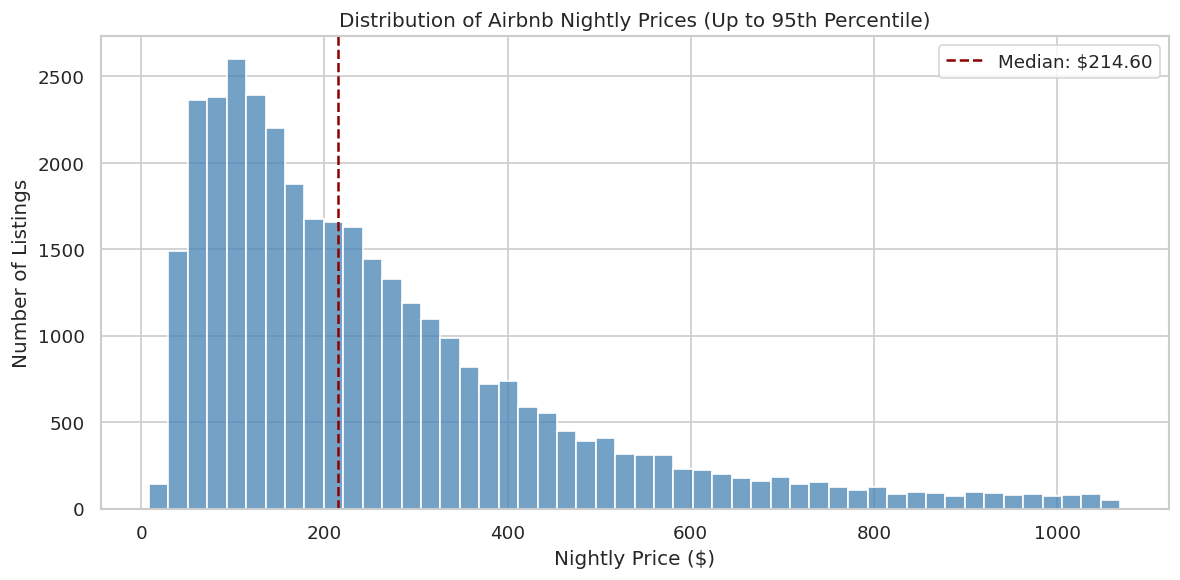

95th percentile price: $1,069.09
Maximum price: $37,787.53


In [ ]:
# Select available nightly prices
prices = df["price"].dropna()

# Calculate the 95th percentile for visualization
price_p95 = prices.quantile(0.95)

# Display the main portion of the price distribution
plt.figure(figsize=(10, 5))

sns.histplot(
    prices[prices <= price_p95],
    bins=50,
    color="steelblue"
)

plt.axvline(
    prices.median(),
    color="darkred",
    linestyle="--",
    label=f"Median: ${prices.median():,.2f}"
)

plt.title("Distribution of Airbnb Nightly Prices (Up to 95th Percentile)")
plt.xlabel("Nightly Price ($)")
plt.ylabel("Number of Listings")
plt.legend()
plt.tight_layout()
plt.show()

print(f"95th percentile price: ${price_p95:,.2f}")
print(f"Maximum price: ${prices.max():,.2f}")


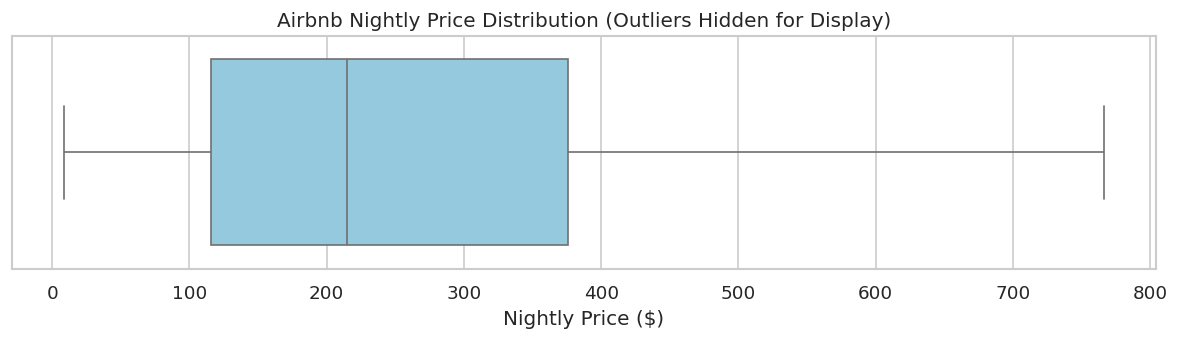

In [ ]:

# Visualize price variation and potential outliers
plt.figure(figsize=(10, 3))

sns.boxplot(
    x=prices,
    color="skyblue",
    showfliers=False
)

plt.title("Airbnb Nightly Price Distribution (Outliers Hidden for Display)")
plt.xlabel("Nightly Price ($)")
plt.tight_layout()
plt.show()


**Price distribution findings**

The countywide nightly price distribution has a long right tail. The 95th percentile is USD 1,069.09, and the maximum observed price is USD 37,787.53. The histogram stops at the 95th percentile for readability. The pricing regressions use the natural logarithm of positive nightly prices.

## 3.6 Room Types and Neighborhoods
### 3.6.1 Room Type Distribution

Airbnb listings offer different accommodation types, including entire homes or apartments, private rooms, shared rooms, and hotel rooms.

We examine the frequency of each room type to understand the composition of the original dataset.

,Listing Count
room_type,
Entire home/apt,32303
Private room,10755
Hotel room,412
Shared room,311


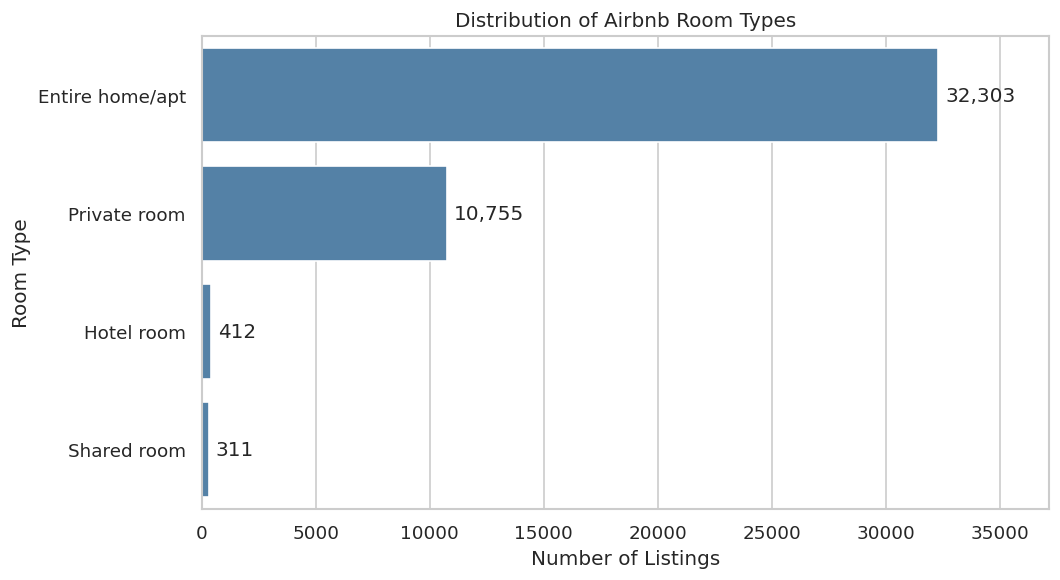

In [ ]:

# Count listings by room type
room_counts = df["room_type"].value_counts()

display(room_counts.to_frame("Listing Count"))

# Create bar chart
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=room_counts.values,
    y=room_counts.index,
    color="steelblue"
)

for i, count in enumerate(room_counts.values):
    ax.text(
        count + 300, i,
        f"{count:,}",
        va="center"
    )

plt.title("Distribution of Airbnb Room Types")
plt.xlabel("Number of Listings")
plt.ylabel("Room Type")
plt.xlim(0, room_counts.max() * 1.15)
plt.tight_layout()
plt.show()


### 3.6.2 Neighborhood Distribution
Because our research focuses on the City of Los Angeles, we examine which neighborhoods contain the highest number of Airbnb listings within that geographic group.

This visualization provides an initial overview of listing concentration and highlights why geographic location may be an important variable in subsequent analyses.

We temporarily select City of Los Angeles observations for this visualization. The permanent analysis dataset will be created in Section 4.

,Listing Count
neighbourhood_cleansed,
Hollywood,1635
Venice,1491
Downtown,1065
Exposition Park,923
Hollywood Hills West,659
Hollywood Hills,657
Mid-City,605
Westwood,530
Woodland Hills,519


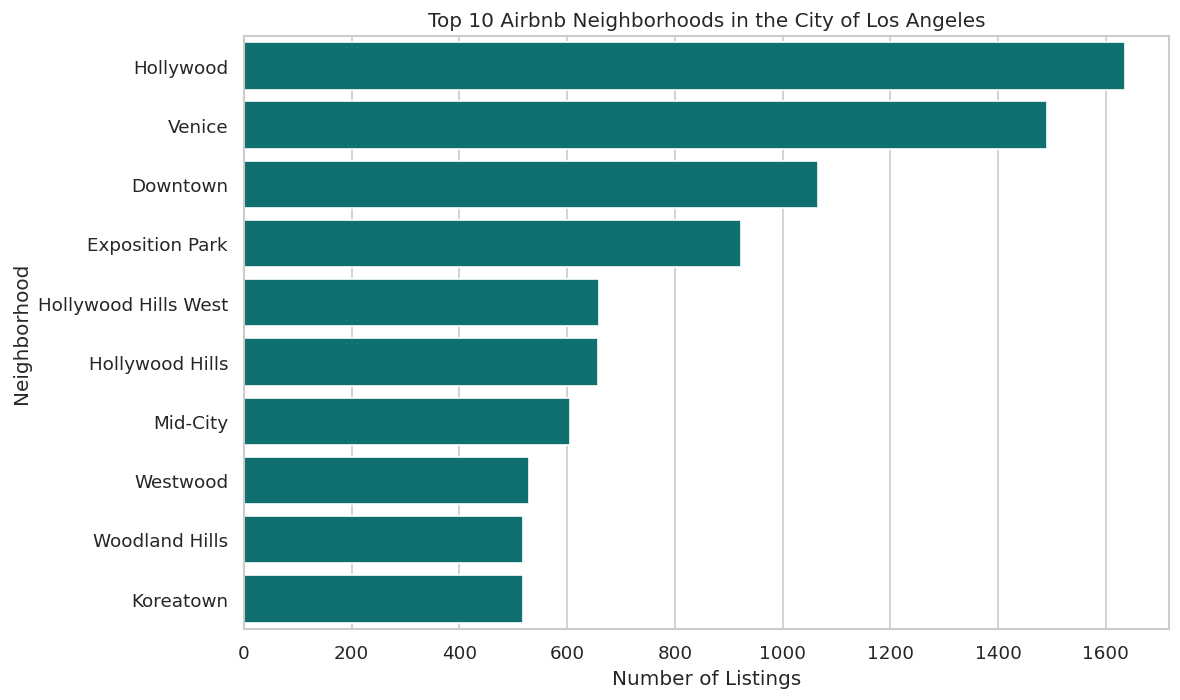

In [ ]:

# Temporary City of Los Angeles subset for EDA
city_preview = df[
    df["neighbourhood_group_cleansed"] == "City of Los Angeles"
]

# Find the 10 neighborhoods with the most listings
top_neighborhoods = (
    city_preview["neighbourhood_cleansed"]
    .value_counts()
    .head(10)
)

display(top_neighborhoods.to_frame("Listing Count"))

# Visualize the top neighborhoods
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=top_neighborhoods.values,
    y=top_neighborhoods.index,
    color="teal"
)

plt.title("Top 10 Airbnb Neighborhoods in the City of Los Angeles")
plt.xlabel("Number of Listings")
plt.ylabel("Neighborhood")
plt.tight_layout()
plt.show()


## 3.7 Initial Exploration Summary

Our initial exploration identified several important characteristics of the Airbnb listings dataset:

1. Geographic coverage: The original dataset contains listings from multiple geographic areas. Only observations classified as City of Los Angeles will be included in the primary research analyses.

2. Missing data: Important variables, including nightly price and guest ratings, contain missing observations. The numeric bathroom variable is entirely missing and requires special attention.

3. Price distribution: Nightly prices are highly right-skewed, with a mean substantially higher than the median and several unusually high observations.

4. Room types: Entire homes and apartments account for the majority of listings, suggesting that accommodation type should be considered in pricing comparisons.

5. Geographic differences: Listings are distributed across multiple neighborhoods, indicating that location may contribute to observed variation in nightly prices.

These findings guide the data preparation decisions in the next section, including geographic filtering, missing-value handling, feature engineering, and price transformation.

# 4. Data Cleaning & Feature Engineering
This section prepares the Airbnb listings dataset for the four research-question analyses.

Based on our initial exploratory analysis, the original dataset requires several preparation steps, including geographic filtering, price transformation, bathroom extraction, categorical encoding, and amenity grouping.

Our cleaning process focuses on the following objectives:
1. Restrict the dataset to Airbnb listings within the City of Los Angeles.
2. Prepare numerical variables needed for statistical analysis.
3. Convert categorical host information into numerical indicators.
4. Identify six amenity categories consistently across listings.
5. Create standardized datasets for the pricing and guest rating analyses.
6. Validate the final variables before conducting statistical tests and regression models.
We preserve the original dataset (df) and create a separate cleaned dataframe (data). This ensures that the original observations remain available for reference.

Missing observations are not automatically replaced with estimated values. Instead, we retain available information and apply complete-case filtering when preparing the regression datasets.


## 4.1 Filter to the City of Los Angeles
The original dataset includes listings from the City of Los Angeles, other cities, and unincorporated areas.

Since our research focuses specifically on the City of Los Angeles, we retain observations where neighbourhood_group_cleansed equals "City of Los Angeles".

We create a new dataframe named data, leaving the original dataframe unchanged. All subsequent cleaning and feature engineering steps will be applied to this City of Los Angeles subset.

In [ ]:

# Filter listings to the City of Los Angeles
data = df.loc[
    df["neighbourhood_group_cleansed"] == "City of Los Angeles"
].copy()

# Verify the filtered dataset
print(f"Original dataset: {len(df):,} listings")
print(f"City of Los Angeles: {len(data):,} listings")

# Confirm geographic filtering
print("\nGeographic groups:")
display(data["neighbourhood_group_cleansed"].value_counts())

assert (
    data["neighbourhood_group_cleansed"]
    == "City of Los Angeles"
).all()


Original dataset: 43,781 listings
City of Los Angeles: 21,687 listings

Geographic groups:


,count
neighbourhood_group_cleansed,
City of Los Angeles,21687


## 4.2 Clean Nightly Prices
Nightly listing price is the primary outcome variable in Research Questions 1–3.

We first convert the price variable to a numeric format and identify missing or nonpositive observations. Since a natural logarithm cannot be calculated for zero or negative values, these observations are treated as missing for price-based analyses.

Our exploratory analysis showed that nightly prices are highly right-skewed. To reduce this skewness and support regression analysis, we create a new variable, log_price, representing the natural logarithm of nightly price.

The original price variable is retained for descriptive statistics, pivot tables, and visualizations, while log_price will be used as the dependent variable in the primary pricing regressions.

In [ ]:

# Ensure nightly price is numerical
data["price"] = pd.to_numeric(
    data["price"],
    errors="coerce"
)

# Identify invalid nonpositive prices
invalid_prices = data["price"].notna() & (data["price"] <= 0)

print("Nonpositive prices:", invalid_prices.sum())

# Treat nonpositive values as missing
data.loc[invalid_prices, "price"] = np.nan

# Create the natural logarithm of nightly price
data["log_price"] = np.log(data["price"])

# Summarize price variables
display(
    data[["price", "log_price"]]
    .describe()
    .round(2)
)

print("Missing prices:", data["price"].isna().sum())
print("Available prices:", data["price"].notna().sum())


Nonpositive prices: 0


,price,log_price
count,17718.00,17718.00
mean,351.72,5.29
std,634.79,0.99
min,8.57,2.15
25%,97.98,4.58
50%,181.08,5.20
75%,364.74,5.90
max,18395.85,9.82


Missing prices: 3969
Available prices: 17718


## 4.3 Clean Property Characteristics

### 4.3.1 Bathroom Counts

The dataset contains a numerical bathrooms column, but this column has no available values.

However, bathrooms_text provides descriptions such as "1 bath," "2 baths," "1 private bath," and "1.5 shared baths."

We extract the numerical portion of these descriptions to create a new variable, bathrooms_num.

Descriptions indicating a half-bath without a numerical prefix are assigned a value of 0.5.

This approach preserves the bathroom information needed for property comparisons and multiple regression.

In [ ]:

# Extract numerical bathroom counts
data["bathrooms_num"] = pd.to_numeric(
    data["bathrooms_text"].str.extract(
        r"(\d+(?:\.\d+)?)"
    )[0],
    errors="coerce"
)

# Handle half-baths without a numerical prefix
half_bath_mask = data["bathrooms_text"].str.fullmatch(
    r"(?:private |shared )?half[- ]bath",
    case=False,
    na=False
)

data.loc[half_bath_mask, "bathrooms_num"] = 0.5

# Review bathroom conversion
bathroom_check = (
    data[["bathrooms_text", "bathrooms_num"]]
    .drop_duplicates()
    .sort_values("bathrooms_num")
)

display(bathroom_check.head(30))

print(
    "Missing bathroom counts:",
    data["bathrooms_num"].isna().sum()
)


,bathrooms_text,bathrooms_num
398,0 shared baths,0.0
55,0 baths,0.0
141,Half-bath,0.5
1982,Shared half-bath,0.5
10029,Private half-bath,0.5
16,1 private bath,1.0
0,1 shared bath,1.0
2,1 bath,1.0
14,1.5 baths,1.5
109,1.5 shared baths,1.5


Missing bathroom counts: 16


### 4.3.2 Bedrooms and Guest Capacity

We examine the bedrooms and accommodates variables to ensure that they are suitable for numerical analysis.

We retain the original bedroom and guest capacity information rather than filling missing values with arbitrary estimates.

Missing values will be handled when creating complete-case samples for regression analysis.

In [ ]:

# Ensure property characteristics are numerical
property_columns = [
    "bedrooms",
    "bathrooms_num",
    "accommodates"
]

for col in property_columns:
    data[col] = pd.to_numeric(
        data[col],
        errors="coerce"
    )

# Check missing values
print("Missing property characteristics:")
display(data[property_columns].isna().sum())

# Examine descriptive statistics
print("\nProperty characteristics summary:")
display(data[property_columns].describe().round(2))


Missing property characteristics:


,0
bedrooms,30
bathrooms_num,16
accommodates,0



Property characteristics summary:


,bedrooms,bathrooms_num,accommodates
count,21657.00,21671.00,21687.00
mean,1.78,1.72,4.07
std,1.39,1.33,2.96
min,0.00,0.00,1.00
25%,1.00,1.00,2.00
50%,1.00,1.00,3.00
75%,2.00,2.00,6.00
max,24.00,24.00,16.00


The regression models use listings with observed values for all required predictors. Listings with unknown bedroom or bathroom counts are excluded from the shared pricing sample.

## 4.4 Encode Host Characteristics

Superhost status is stored as a categorical variable using "t" and "f" values.

We convert this information into a binary numerical variable named superhost:

* 1: The listing host has Superhost status.

* 0: The listing host does not have Superhost status.

This transformation allows Superhost status to be included in group comparisons and regression models.

In [ ]:

# Convert Superhost status to a binary variable
data["superhost"] = data["host_is_superhost"].map({
    "t": 1,
    "f": 0
})

# Verify the conversion
print("Superhost distribution:")
display(data["superhost"].value_counts(dropna=False))

print("Missing Superhost values:", data["superhost"].isna().sum())


Superhost distribution:


,count
superhost,
0,14325
1,7362


Missing Superhost values: 0


## 4.5 Group and Encode Amenities

The amenities column stores each listing's amenities as a text representation of a list.

To analyze amenities consistently, we first convert these strings into Python lists.

We then group related amenities into six categories: Wi-Fi, parking, pool/spa, air conditioning, kitchen, and washer/dryer.

Each category is represented by a binary variable:

* 1: At least one relevant amenity is advertised.

* 0: No matching amenity is detected.

A value of 0 indicates that the amenity was not advertised or detected in the listing data; it does not necessarily establish that the property lacks the amenity.

In [ ]:

import json
import re

# Convert the amenities text into a Python list
def parse_amenities(value):
    if pd.isna(value):
        return []

    try:
        result = json.loads(value)

        if isinstance(result, list):
            return [
                str(item).lower().strip()
                for item in result
            ]

        return []

    except (ValueError, TypeError):
        return []


# Apply the function to every listing
data["amenities_list"] = data["amenities"].apply(
    parse_amenities
)

# Preview the converted amenities
display(
    data[["amenities", "amenities_list"]].head(3)
)

print(
    "Listings with empty parsed amenity lists:",
    data["amenities_list"].apply(len).eq(0).sum()
)


,amenities,amenities_list
0,"[""1801 Beekman Luxury Spa Goat Milk Soap & Han...",[1801 beekman luxury spa goat milk soap & hand...
2,"[""Children\u2019s books and toys"", ""Hot water""...","[children’s books and toys, hot water, first a..."
3,"[""Baking sheet"", ""Refrigerator"", ""Private pati...","[baking sheet, refrigerator, private patio or ..."


Listings with empty parsed amenity lists: 25


### 4.5.2 Define the six amenity groups

In [ ]:

# Define six standardized amenity categories
amenity_groups = {
    "wifi": ["wifi", "wi-fi"],

    "parking": ["parking"],

    "pool_spa": [
        "pool", "swimming pool",
        "hot tub", "jacuzzi", "spa access"
    ],

    "air_conditioning": ["air conditioning"],

    "kitchen": ["kitchen"],

    "washer_dryer": [
        "washer", "dryer",
        "washing machine", "drying machine"
    ]
}

# Shared column names for all research questions
amenity_columns = list(amenity_groups.keys())

print("Amenity categories:")
print(amenity_columns)


Amenity categories:
['wifi', 'parking', 'pool_spa', 'air_conditioning', 'kitchen', 'washer_dryer']


### 4.5.3 Create the amenity matching function

In [ ]:

# Identify whether a listing advertises an amenity group
def has_amenity(items, group):

    for item in items:

        item = item.lower().strip()

        # Exclude explicitly unavailable amenities
        if re.search(
            r"\b(not available|not included)\b",
            item
        ):
            continue

        # Wi-Fi
        if group == "wifi":
            if re.search(r"\b(?:wifi|wi-fi)\b", item):
                return 1

        # Parking
        elif group == "parking":
            if "parking" in item:
                return 1

        # Pool / Spa
        elif group == "pool_spa":

            # Exclude unrelated pool descriptions
            if re.search(
                r"\bpool\s+(?:table|view|toys?|cover)\b",
                item
            ):
                continue

            if (
                re.search(
                    r"^(?:(?:private|shared|outdoor|indoor|heated)\s+)*"
                    r"(?:pool|swimming pool|hot\s*tub|jacuzzi)\b",
                    item
                )
                or item == "spa access"
            ):
                return 1

        # Air conditioning
        elif group == "air_conditioning":
            if "air conditioning" in item:
                return 1

        # Kitchen
        elif group == "kitchen":
            if (
                item == "kitchen"
                or item.startswith("kitchen ")
            ):
                return 1

        # Clothes washer or dryer
        elif group == "washer_dryer":
            if re.search(
                r"^(?:(?:free|paid)\s+)?"
                r"(?:washer|dryer|washing machine|drying machine)\b",
                item
            ):
                return 1

    return 0


### 4.5.4 Create binary indicators

In [ ]:

# Create six binary amenity variables
for group in amenity_columns:
    data[group] = data["amenities_list"].apply(
        lambda items: has_amenity(items, group)
    )

# Preview the new variables
display(
    data[["id"] + amenity_columns].head()
)

# Confirm all indicators contain only 0 or 1
for col in amenity_columns:
    assert data[col].isin([0, 1]).all()

print("All six amenity indicators created successfully.")


,id,wifi,parking,pool_spa,air_conditioning,kitchen,washer_dryer
0,2708,1,1,1,1,1,1
2,6033,1,1,1,1,0,1
3,6931,1,1,1,1,1,1
5,153412,1,1,0,0,1,1
9,164946,1,1,0,0,1,1


All six amenity indicators created successfully.


### 4.5.5 Verify amenity frequencies

,Listing Count,Percentage (%)
wifi,21412,98.73
kitchen,19603,90.39
parking,18879,87.05
air_conditioning,18101,83.46
washer_dryer,17913,82.60
pool_spa,6368,29.36


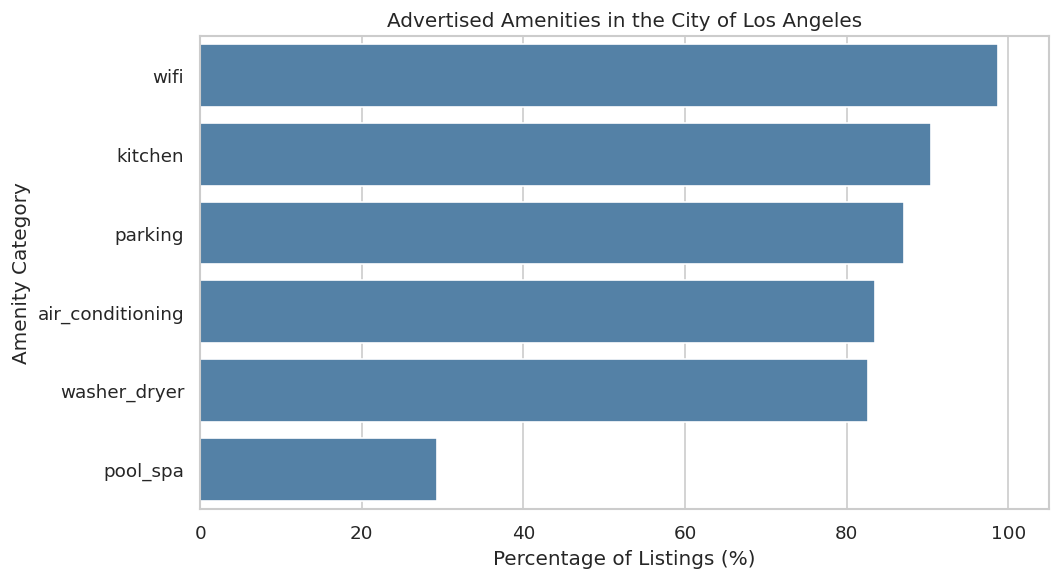

In [ ]:

# Summarize amenity frequencies
amenity_summary = pd.DataFrame({
    "Listing Count": data[amenity_columns].sum(),
    "Percentage (%)": (
        data[amenity_columns].mean() * 100
    ).round(2)
})

amenity_summary = amenity_summary.sort_values(
    "Listing Count",
    ascending=False
)

display(amenity_summary)

# Visualize frequency of advertised amenities
plt.figure(figsize=(9, 5))

sns.barplot(
    data=amenity_summary.reset_index(),
    x="Percentage (%)",
    y="index",
    color="steelblue"
)

plt.title("Advertised Amenities in the City of Los Angeles")
plt.xlabel("Percentage of Listings (%)")
plt.ylabel("Amenity Category")
plt.xlim(0, 105)
plt.tight_layout()
plt.show()


**Amenity Grouping Results**

Wi-Fi is the most commonly advertised amenity category, appearing in approximately 98.7% of City of Los Angeles listings.

Kitchen, parking, air conditioning, and washer/dryer amenities are also frequently advertised.

Pool/spa is less common, appearing in approximately 29.4% of listings.

Because several amenity categories are widely available, particularly Wi-Fi, differences in their associations with nightly prices should be interpreted carefully. The regression analyses will help evaluate these relationships while accounting for other property characteristics.

## 4.6 Create Amenity Count Variables
In addition to the six binary amenity indicators, we calculate two variables describing the number of amenities advertised by each listing.

amenity_count represents the total number of entries in the listing's parsed amenities list.

grouped_amenity_count represents the number of our six selected amenity categories detected for each listing, ranging from 0 to 6.

These variables provide descriptive information about amenity availability. Our primary amenity regression models will use the six individual indicators rather than the grouped count to estimate category-specific associations.

In [ ]:

# Count all amenity entries
data["amenity_count"] = (
    data["amenities_list"].apply(len)
)

# Count how many of the six categories are detected
data["grouped_amenity_count"] = (
    data[amenity_columns].sum(axis=1)
)

# Preview counts
display(
    data[
        [
            "amenity_count",
            "grouped_amenity_count"
        ]
    ].head()
)

# Summarize amenity counts
display(
    data[
        [
            "amenity_count",
            "grouped_amenity_count"
        ]
    ].describe().round(2)
)


,amenity_count,grouped_amenity_count
0,77,6
2,32,5
3,72,6
5,56,4
9,28,4


,amenity_count,grouped_amenity_count
count,21687.00,21687.00
mean,37.44,4.72
std,17.92,1.04
min,0.00,0.00
25%,23.00,4.00
50%,37.00,5.00
75%,51.00,5.00
max,126.00,6.00


## 4.7 Prepare Analysis Datasets

After filtering to the City of Los Angeles, 21,687 listings remain. The pricing sample (`price_data`) contains 17,678 listings with a positive nightly price and complete information for the shared model variables, including neighborhood. All pricing regressions use this sample so their fit statistics can be compared directly.

The guest ratings sample (`ratings_data`) contains the 12,133 listings in the pricing sample with an observed overall guest rating.

In [ ]:
# Define shared predictors for the regression models
predictors = [
    "bedrooms",
    "bathrooms_num",
    "accommodates",
    "room_type",
    "superhost",
    "availability_365",
    "neighbourhood_cleansed",
] + amenity_columns
# Pricing dataset: complete outcome and predictors
price_data = data.dropna(
    subset=["log_price"] + predictors
).copy()
# Ratings dataset: complete price-model sample
# with an additional observed guest rating
ratings_data = price_data.dropna(
    subset=["review_scores_rating"]
).copy()
# Compare dataset sizes
sample_summary = pd.DataFrame({
    "Dataset": [
        "Original dataset",
        "City of Los Angeles",
        "Pricing model",
        "Guest ratings model"
    ],
    "Listings": [
        len(df),
        len(data),
        len(price_data),
        len(ratings_data)
    ]
})
display(sample_summary)

,Dataset,Listings
0,Original dataset,43781
1,City of Los Angeles,21687
2,Pricing model,17678
3,Guest ratings model,12133


## 4.8 Validate the Cleaned Data

In [ ]:

# Check geographic consistency
assert data["neighbourhood_group_cleansed"].eq(
    "City of Los Angeles"
).all()

# Ensure valid prices in the pricing dataset
assert price_data["price"].gt(0).all()

# Check six amenity indicators
assert len(amenity_columns) == 6

for col in amenity_columns:
    assert data[col].isin([0, 1]).all()

# Verify grouped amenity count
assert (
    data["grouped_amenity_count"]
    == data[amenity_columns].sum(axis=1)
).all()

# Check complete-case datasets
assert price_data[
    ["log_price"] + predictors
].notna().all().all()

assert ratings_data[
    ["review_scores_rating", "log_price"] + predictors
].notna().all().all()

# Test important amenity classifications
assert has_amenity(["Pool table"], "pool_spa") == 0
assert has_amenity(["Hot tub"], "pool_spa") == 1
assert has_amenity(["Jacuzzi"], "pool_spa") == 1

assert has_amenity(
    ["Washing machine"], "washer_dryer"
) == 1

assert has_amenity(
    ["Drying machine"], "washer_dryer"
) == 1

assert has_amenity(
    ["Hair dryer", "Dishwasher"], "washer_dryer"
) == 0

print("All validation checks passed.")

print(f"City of LA listings: {len(data):,}")
print(f"Pricing sample: {len(price_data):,}")
print(f"Ratings sample: {len(ratings_data):,}")


All validation checks passed.
City of LA listings: 21,687
Pricing sample: 17,678
Ratings sample: 12,133


# 5. Research Question 1 — Property Characteristics and Nightly Prices

## 5.1 Research Question and Methodology
**Research Question 1**: How do property characteristics, including bedrooms, bathrooms, guest capacity, and room type, relate to Airbnb nightly prices in Los Angeles?

The objective of this analysis is to examine how physical property characteristics are associated with differences in nightly Airbnb listing prices.

We focus on four key characteristics:
- Bedrooms: Number of bedrooms available in the listing.
- Bathrooms: Number of bathrooms, extracted from the original bathroom descriptions.
- Guest Capacity: Maximum number of guests the listing can accommodate.
- Room Type: Whether the listing is an entire home/apartment, private room, shared room, or hotel room.

We use descriptive statistics and pivot tables to summarize pricing differences across listing characteristics. Bar charts are used to visualize these comparisons, followed by one-way ANOVA to examine differences between room types.

Finally, we apply multiple linear regression with log-transformed nightly price as the dependent variable to evaluate associations while accounting for the other property characteristics. A second model includes neighborhood controls to examine whether the relationships remain consistent after accounting for location.

The analyses use the cleaned City of Los Angeles pricing dataset (price_data) prepared in Section 4.

In [ ]:
price_data[
    [
        "price",
        "bedrooms",
        "bathrooms_num",
        "accommodates",
    ]
].describe().round(2)

,price,bedrooms,bathrooms_num,accommodates
count,17678.00,17678.00,17678.00,17678.00
mean,351.67,1.82,1.75,4.16
std,634.31,1.42,1.37,3.04
min,8.57,0.00,0.00,1.00
25%,97.99,1.00,1.00,2.00
50%,181.17,1.00,1.00,3.00
75%,364.84,2.00,2.00,6.00
max,18395.85,24.00,21.00,16.00


## 5.2 Descriptive Statistics of Property Characteristics

In [ ]:

# Select numerical variables for RQ1
rq1_variables = [
    "price",
    "bedrooms",
    "bathrooms_num",
    "accommodates"
]

# Generate descriptive statistics
rq1_summary = (
    price_data[rq1_variables]
    .describe()
    .T
    .round(2)
)

display(rq1_summary)

print(f"Listings included in RQ1: {len(price_data):,}")


,count,mean,std,min,25%,50%,75%,max
price,17678.0,351.67,634.31,8.57,97.99,181.17,364.84,18395.85
bedrooms,17678.0,1.82,1.42,0.00,1.00,1.00,2.00,24.00
bathrooms_num,17678.0,1.75,1.37,0.00,1.00,1.00,2.00,21.00
accommodates,17678.0,4.16,3.04,1.00,2.00,3.00,6.00,16.00


Listings included in RQ1: 17,678


## 5.3 Pivot Tables and Visualizations

### 5.3.1 Nightly Price by Room Type

We first compare nightly prices across Airbnb room types.

Because the nightly price distribution is positively skewed, we report both mean and median prices. The median provides a useful measure of typical listing prices because it is less sensitive to unusually expensive properties.

We use a pivot table to summarize listing counts and pricing differences, followed by a horizontal bar chart comparing median nightly prices.

In [ ]:

# Summarize nightly prices by room type
room_pivot = (
    price_data.groupby("room_type")["price"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median"
    )
    .sort_values("Median", ascending=False)
    .round(2)
)

display(room_pivot)


,Count,Mean,Median
room_type,,,
Hotel room,147,627.62,299.00
Entire home/apt,13025,430.41,236.27
Private room,4315,118.18,68.38
Shared room,191,45.04,30.23


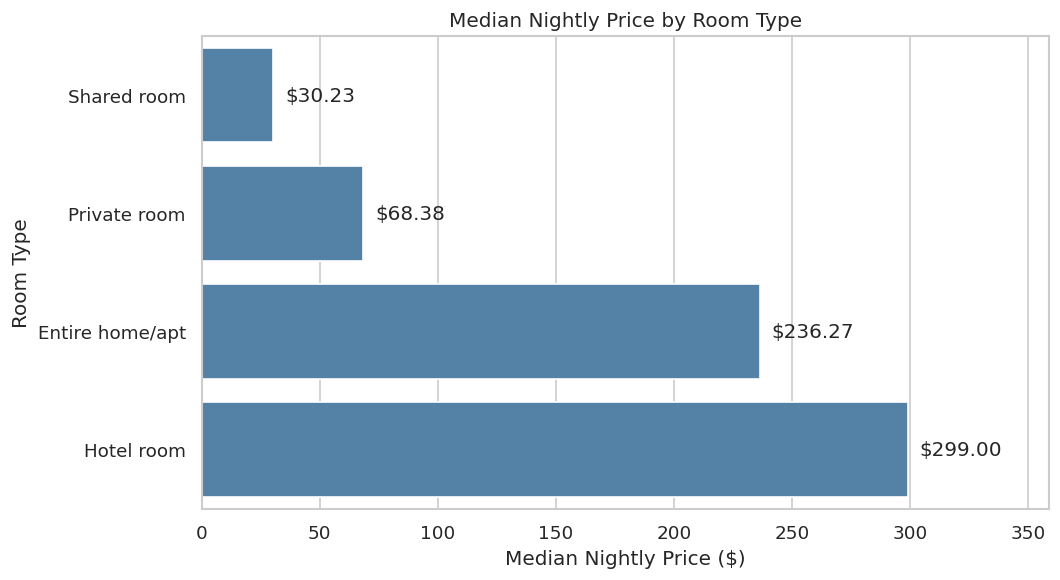

In [ ]:

# Sort room types by median nightly price
room_order = room_pivot.sort_values("Median")

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    x=room_order["Median"],
    y=room_order.index,
    color="steelblue"
)

# Display median price labels
for i, value in enumerate(room_order["Median"]):
    ax.text(
        value + 5,
        i,
        f"${value:,.2f}",
        va="center"
    )

plt.title("Median Nightly Price by Room Type")
plt.xlabel("Median Nightly Price ($)")
plt.ylabel("Room Type")
plt.xlim(0, room_order["Median"].max() * 1.20)
plt.tight_layout()
plt.show()


**Room type findings**

Median nightly prices were USD 299.00 for hotel rooms, USD 236.27 for entire homes or apartments, USD 68.38 for private rooms, and USD 30.23 for shared rooms. Hotel and shared rooms had relatively few observations. These are unadjusted comparisons.

### 5.3.2 Nightly Price by Number of Bedrooms

We examine how nightly listing prices vary with the number of bedrooms.



In [ ]:

# Summarize prices by bedroom count
bedroom_pivot = (
    price_data.groupby("bedrooms")["price"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median"
    )
    .sort_index()
    .round(2)
)

display(bedroom_pivot)


,Count,Mean,Median
bedrooms,,,
0.0,1457,148.69,104.35
1.0,8564,148.47,110.70
2.0,3250,303.99,243.30
3.0,2179,520.77,407.00
4.0,1286,812.38,614.49
5.0,593,1336.52,1061.70
6.0,211,1710.57,1174.00
7.0,84,2389.00,1676.86
8.0,24,3492.10,2820.25


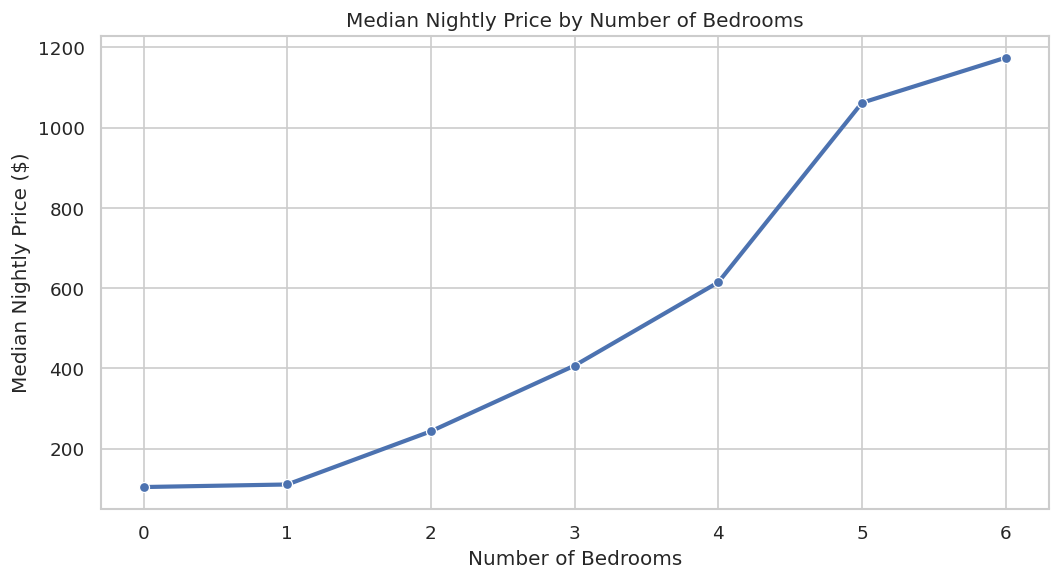

In [ ]:

# Focus visualization on 0 to 6 bedrooms
bedroom_plot = bedroom_pivot.loc[
    bedroom_pivot.index.isin(range(0, 7))
]

plt.figure(figsize=(9, 5))

sns.lineplot(
    x=bedroom_plot.index,
    y=bedroom_plot["Median"],
    marker="o",
    linewidth=2.5
)

plt.title("Median Nightly Price by Number of Bedrooms")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Median Nightly Price ($)")
plt.xticks(range(0, 7))
plt.tight_layout()
plt.show()


**Bedroom findings**

Median nightly prices generally increased with bedroom count. The medians were USD 110.70 for one bedroom, USD 243.30 for two, and USD 407.00 for three. Room type, capacity, and location may also contribute to these differences.

### 5.3.3 Nightly Price by Number of Bathrooms

We examine the relationship between bathroom count and nightly listing prices.

,Count,Mean,Median
bathrooms_num,,,
0.0,74,210.29,121.15
0.5,54,152.05,78.24
1.0,10462,161.72,121.56
1.5,614,216.67,164.75
2.0,3057,345.16,283.11
2.5,715,514.92,422.00
3.0,940,580.87,465.31
3.5,394,773.65,636.10
4.0,362,920.62,757.64


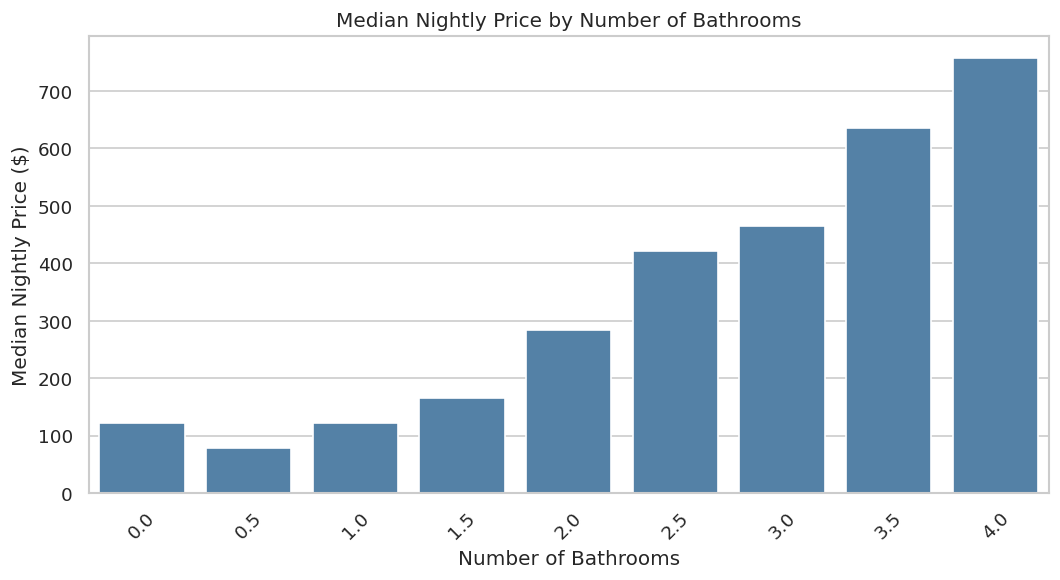

In [ ]:

# Summarize nightly prices by bathroom count
bathroom_pivot = (
    price_data.groupby("bathrooms_num")["price"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median"
    )
    .sort_index()
    .round(2)
)

display(bathroom_pivot)

# Display bathroom groups from 0 to 4
bathroom_plot = bathroom_pivot.loc[
    bathroom_pivot.index <= 4
]

plt.figure(figsize=(9, 5))

sns.barplot(
    x=bathroom_plot.index.astype(str),
    y=bathroom_plot["Median"],
    color="steelblue"
)

plt.title("Median Nightly Price by Number of Bathrooms")
plt.xlabel("Number of Bathrooms")
plt.ylabel("Median Nightly Price ($)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Bathroom findings**

The median nightly price was USD 121.56 for listings with one bathroom, USD 283.11 for two, and USD 465.31 for three. Median prices generally rose with bathroom count, with exceptions across individual categories.

### 5.3.4 Nightly Price by Guest Capacity

Guest capacity indicates the maximum number of guests a listing can accommodate.

,Count,Mean,Median
accommodates,,,
1,1811,77.25,65.89
2,6053,145.70,110.14
3,1259,192.38,159.17
4,2840,271.11,204.98
5,778,328.76,274.30
6,1870,483.88,359.60
7,354,455.63,331.39
8,1174,755.00,549.60
9,168,657.05,435.95


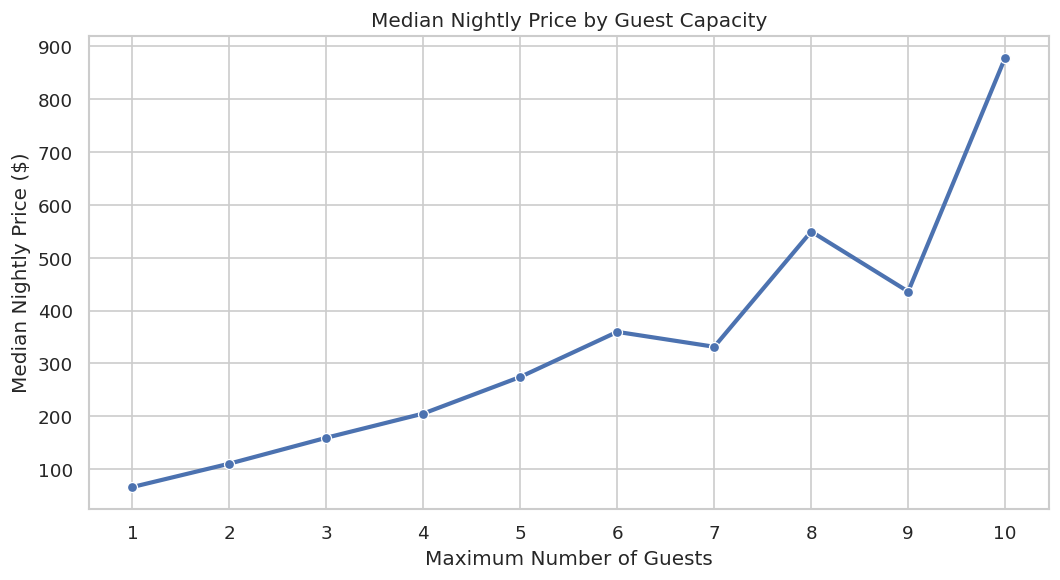

In [ ]:

# Summarize nightly prices by guest capacity
capacity_pivot = (
    price_data.groupby("accommodates")["price"]
    .agg(
        Count="count",
        Mean="mean",
        Median="median"
    )
    .sort_index()
    .round(2)
)

display(capacity_pivot)

# Focus visualization on capacity from 1 to 10
capacity_plot = capacity_pivot.loc[
    capacity_pivot.index.isin(range(1, 11))
]

plt.figure(figsize=(9, 5))

sns.lineplot(
    x=capacity_plot.index,
    y=capacity_plot["Median"],
    marker="o",
    linewidth=2.5
)

plt.title("Median Nightly Price by Guest Capacity")
plt.xlabel("Maximum Number of Guests")
plt.ylabel("Median Nightly Price ($)")
plt.xticks(range(1, 11))
plt.tight_layout()
plt.show()


**Guest capacity findings**

Median nightly prices were USD 110.14 for listings accommodating two guests, USD 204.98 for four guests, and USD 359.60 for six guests. The median did not rise at every capacity level.

## 5.4 ANOVA — Room Type and Nightly Prices

We use one-way Analysis of Variance (ANOVA) to test whether mean log-transformed nightly prices differ across Airbnb room types.

Our hypotheses are:

* Null hypothesis (H₀): Mean log nightly prices are equal across all room types.

* Alternative hypothesis (H₁): At least one room type has a different mean log nightly price.

We use log_price as the dependent variable because the original nightly price distribution is highly right-skewed.

A significance level of 0.05 is used to evaluate the statistical evidence against the null hypothesis.

In [ ]:

from statsmodels.stats.anova import anova_lm

# Fit one-way ANOVA model
anova_model = smf.ols(
    formula="log_price ~ C(room_type)",
    data=price_data
).fit()

# Generate ANOVA table
anova_results = anova_lm(
    anova_model,
    typ=2
)

display(anova_results)

# Extract F statistic and p-value
f_stat = anova_results.loc["C(room_type)", "F"]
p_value = anova_results.loc["C(room_type)", "PR(>F)"]

print(f"F-statistic: {f_stat:.2f}")
print(f"P-value: {p_value:.3e}")

if p_value < 0.05:
    print("Reject H0: Mean log prices differ by room type.")
else:
    print("Fail to reject H0.")


,sum_sq,df,F,PR(>F)
C(room_type),5216.856278,3.0,2559.395082,0.0
Residual,12008.399758,17674.0,NaN,NaN


F-statistic: 2559.40
P-value: 0.000e+00
Reject H0: Mean log prices differ by room type.


**ANOVA Results**

The one-way ANOVA reveals a statistically significant difference in mean log nightly prices across room types, F(3, 17674) = 2559.40, p < 0.001.

We therefore reject the null hypothesis that all room types have equal mean log nightly prices.

This finding provides statistical evidence that room type is associated with Airbnb nightly prices.

However, ANOVA does not identify which specific pairs of room types differ, nor does it control for other property characteristics. These relationships are examined further using multiple linear regression.

## 5.5 Multiple Linear Regression — Property Characteristics and Nightly Prices

We use multiple linear regression to investigate whether bedrooms, bathrooms, guest capacity, and room type are associated with nightly Airbnb prices when considered together.

The dependent variable is the natural logarithm of nightly price (log_price).

The independent variables include:

* Number of bedrooms

* Number of bathrooms

* Maximum guest capacity

* Room type (categorical)

Room type is included as a categorical variable, with entire homes/apartments serving as the reference category.

In [ ]:
# Define the RQ1 regression formula
rq1_formula = (
    "log_price ~ bedrooms"
    " + bathrooms_num"
    " + accommodates"
    " + C(room_type)"
)
# Fit the multiple linear regression
rq1_model = smf.ols(
    formula=rq1_formula,
    data=price_data
).fit(cov_type="HC3")
rq1_location_model = smf.ols(
    rq1_formula + " + C(neighbourhood_cleansed)", data=price_data
).fit(cov_type="HC3")

display(pd.DataFrame({
    "Observations": [int(rq1_model.nobs), int(rq1_location_model.nobs)],
    "R-squared": [rq1_model.rsquared, rq1_location_model.rsquared],
    "Adjusted R-squared": [rq1_model.rsquared_adj, rq1_location_model.rsquared_adj],
}, index=["Property model", "With neighborhood"]).round(4))

,Observations,R-squared,Adjusted R-squared
Property model,17678,0.6549,0.6547
With neighborhood,17678,0.7368,0.7350


In [ ]:
# Create a simplified coefficient table
rq1_coefficients = pd.DataFrame({
    "Coefficient": rq1_model.params,
    "P-value": rq1_model.pvalues,
    "CI Lower": rq1_model.conf_int()[0],
    "CI Upper": rq1_model.conf_int()[1]
})

# Convert coefficients into percentage differences
rq1_coefficients["Price Difference (%)"] = (
    (np.exp(rq1_coefficients["Coefficient"]) - 1) * 100
)

# Percentage differences apply to predictors; the intercept is the baseline.
rq1_coefficients = rq1_coefficients.drop(index="Intercept")
rq1_coefficients_display = rq1_coefficients.round(4)
rq1_coefficients_display["P-value"] = rq1_coefficients["P-value"].map(lambda p: "< 0.001" if p < 0.001 else f"{p:.4f}")
display(rq1_coefficients_display)

,Coefficient,P-value,CI Lower,CI Upper,Price Difference (%)
C(room_type)[T.Hotel room],0.5563,< 0.001,0.4621,0.6504,74.4156
C(room_type)[T.Private room],-0.6700,< 0.001,-0.6953,-0.6447,-48.8288
C(room_type)[T.Shared room],-1.5323,< 0.001,-1.6094,-1.4552,-78.3967
bedrooms,0.1478,< 0.001,0.1161,0.1795,15.9264
bathrooms_num,0.1354,< 0.001,0.1158,0.1549,14.4974
accommodates,0.0924,< 0.001,0.0804,0.1043,9.6782


**Multiple Regression Results**

The property-only model explains 65.5% of the in-sample variation in log nightly asking prices. Holding the other included property characteristics constant, one additional bedroom is associated with a 15.9% higher nightly asking price, one additional bathroom with a 14.5% higher price, and one additional guest of capacity with a 9.7% higher price (all p < 0.001). These percentages use $100(e^\beta - 1)$.

Compared with entire homes or apartments, private and shared rooms have lower adjusted prices, and hotel rooms have higher adjusted prices. The next subsection compares prices across neighborhoods and shows how much location adds to model fit.

## 5.6 Neighborhood and Nightly Prices

We compare median nightly asking prices across the 10 neighborhoods with the most listings in the shared City of Los Angeles pricing sample. Choosing neighborhoods by listing count gives the chart a clear coverage rule. The dashed line shows the median across all listings in the pricing sample.

,Listings,Median nightly asking price (USD)
neighbourhood_cleansed,,
Hollywood Hills West,581,962.41
Venice,1175,300.31
Hollywood Hills,534,276.14
Woodland Hills,455,224.42
Downtown,848,207.44
Hollywood,1325,176.71
Mid-City,492,128.23
Koreatown,426,117.48
Westwood,436,88.50


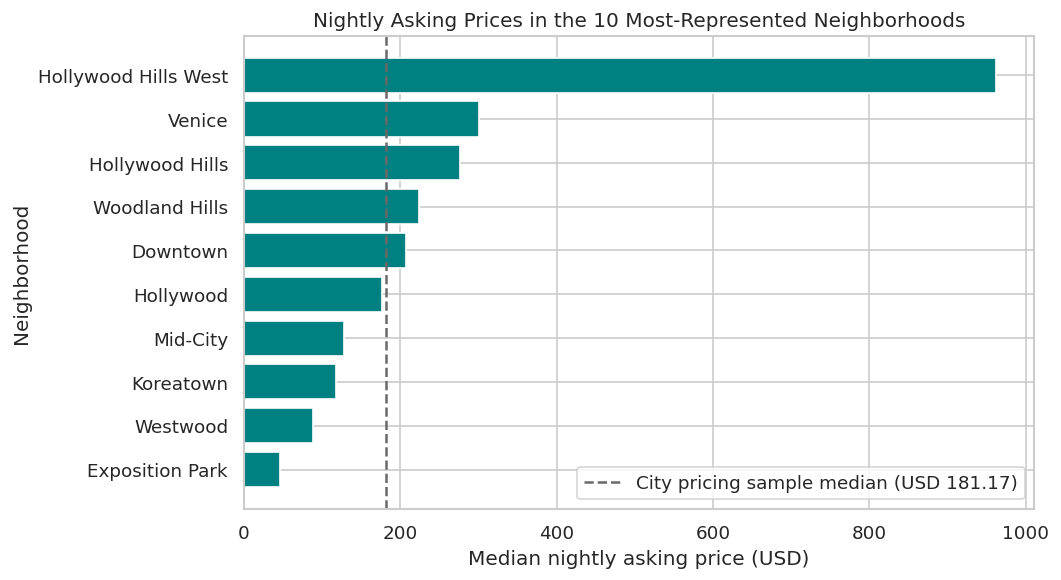

Highest displayed median: Hollywood Hills West (USD 962.41)
Lowest displayed median: Exposition Park (USD 45.87)


In [ ]:
neighborhood_prices = (
    price_data.groupby("neighbourhood_cleansed", observed=True)["price"]
    .agg(Listings="size", Median="median")
    .sort_values("Listings", ascending=False)
    .head(10)
    .sort_values("Median", ascending=False)
)
city_median = price_data["price"].median()

display(neighborhood_prices.rename(
    columns={"Median": "Median nightly asking price (USD)"}
).round(2))

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(neighborhood_prices.index, neighborhood_prices["Median"], color="teal")
ax.invert_yaxis()
ax.axvline(city_median, color="dimgray", linestyle="--",
           label=f"City pricing sample median (USD {city_median:,.2f})")
ax.set(title="Nightly Asking Prices in the 10 Most-Represented Neighborhoods",
       xlabel="Median nightly asking price (USD)", ylabel="Neighborhood")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

highest = neighborhood_prices.iloc[0]
lowest = neighborhood_prices.iloc[-1]
print(f"Highest displayed median: {highest.name} (USD {highest['Median']:,.2f})")
print(f"Lowest displayed median: {lowest.name} (USD {lowest['Median']:,.2f})")

Among the 10 displayed neighborhoods, Hollywood Hills West had the highest median nightly asking price (USD 962.41 across 581 listings), and Exposition Park had the lowest (USD 45.87 across 849 listings). Differences in room type, size, and other characteristics can contribute to this gap.

Using the same 17,678 listings, adding neighborhood indicators to the property model increased in-sample R² from 0.655 to 0.737, a gain of 8.2 percentage points. Adding those indicators to the model that already included amenities and host variables increased in-sample R² from 0.690 to 0.757 (see Section 6.8). These comparisons show that neighborhood adds explanatory value within the sample after accounting for the included listing characteristics.

## 5.7 Research Question 1 — Key Findings

**Research Question**: How do property characteristics, including bedrooms, bathrooms, guest capacity, and room type, relate to Airbnb nightly prices in Los Angeles?

Our analysis found that property characteristics are strongly associated with Airbnb nightly prices in the City of Los Angeles.

Descriptive statistics showed that listings with more bedrooms, bathrooms, and higher guest capacity generally have higher median nightly prices. Room type also showed substantial pricing differences, with hotel rooms and entire homes/apartments typically priced higher than private and shared rooms.

A one-way ANOVA confirmed statistically significant differences in mean log nightly prices across room types (p < 0.001).

The multiple regression analysis found that bedrooms, bathrooms, and guest capacity were all positively associated with nightly prices after controlling for the other included property characteristics.

The property-characteristics model explained approximately 65.5% of the variation in log nightly prices. Adding neighborhood controls improved the model's explanatory power to approximately 73.7%.

**Conclusion**

Property size, accommodation capacity, room type, and location are important characteristics associated with nightly Airbnb pricing.

These findings suggest that hosts and analysts should consider multiple property attributes together when comparing listing prices rather than relying on a single characteristic.

Because the analysis uses observational listing data, the findings describe associations and should not be interpreted as causal effects.

# 6. Research Question 2 — Amenities and Nightly Prices

## 6.1 Research Question and Methodology

How are Wi-Fi, parking, pool/spa, air conditioning, kitchen, and washer/dryer associated with nightly asking prices after adjustment?

Each indicator equals 1 when the amenity is detected in the listing text and 0 otherwise. We compare median prices by amenity, then fit four models on the same pricing sample. Starting with the property-only baseline, we add amenity indicators, host variables, and neighborhood indicators in stages. The outcome is the natural logarithm of nightly asking price.

## 6.2 Amenity Frequencies in the Pricing Sample

Before comparing nightly prices, we examine how frequently each amenity is advertised among the listings included in our pricing analysis.

In [ ]:

# Use the six amenity indicators from Section 4
print("Amenity variables:", amenity_columns)

# Summarize amenities in the pricing sample
rq2_frequency = pd.DataFrame({
    "With Amenity": price_data[amenity_columns].sum(),
    "Without Amenity": (
        1 - price_data[amenity_columns]
    ).sum(),
    "Percentage (%)": (
        price_data[amenity_columns].mean() * 100
    ).round(2)
})

display(rq2_frequency)

print(f"Pricing sample: {len(price_data):,} listings")


Amenity variables: ['wifi', 'parking', 'pool_spa', 'air_conditioning', 'kitchen', 'washer_dryer']


,With Amenity,Without Amenity,Percentage (%)
wifi,17471,207,98.83
parking,15501,2177,87.69
pool_spa,5191,12487,29.36
air_conditioning,14840,2838,83.95
kitchen,15957,1721,90.26
washer_dryer,14606,3072,82.62


Pricing sample: 17,678 listings


## 6.3 Descriptive Price Comparisons by Amenity

For each of the six amenities, the table reports listing counts and median nightly prices for the groups with and without a detected amenity. It also reports the difference between the two medians.

In [ ]:

# Create a summary table for all six amenities
amenity_results = []

for amenity in amenity_columns:

    summary = (
        price_data.groupby(amenity)["price"]
        .agg(["count", "mean", "median"])
        .reindex([0, 1])
    )

    amenity_results.append({
        "Amenity": amenity.replace("_", " ").title(),
        "Without Count": summary.loc[0, "count"],
        "With Count": summary.loc[1, "count"],
        "Without Median": summary.loc[0, "median"],
        "With Median": summary.loc[1, "median"],
        "Median Difference": (
            summary.loc[1, "median"]
            - summary.loc[0, "median"]
        )
    })

amenity_comparison = pd.DataFrame(amenity_results)

display(amenity_comparison.round(2))


,Amenity,Without Count,With Count,Without Median,With Median,Median Difference
0,Wifi,207,17471,132.98,182.17,49.19
1,Parking,2177,15501,118.05,192.72,74.67
2,Pool Spa,12487,5191,146.63,303.00,156.37
3,Air Conditioning,2838,14840,129.86,197.68,67.82
4,Kitchen,1721,15957,172.00,182.61,10.61
5,Washer Dryer,3072,14606,152.80,189.47,36.67


## 6.4 Visualizing Amenity-Related Price Differences

### 6.4.1 Median Nightly Prices With and Without Amenities

We visualize median nightly prices for listings with and without each amenity.

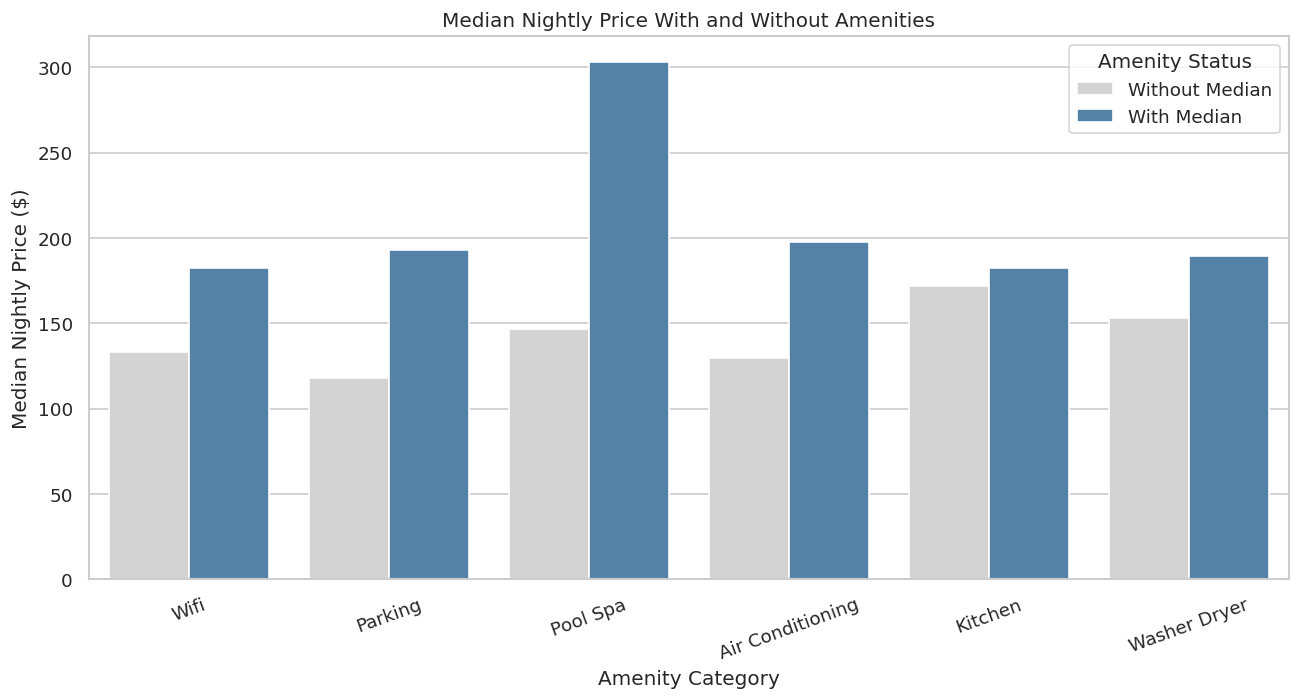

In [ ]:

# Reshape data for grouped bar chart
amenity_plot = amenity_comparison.melt(
    id_vars="Amenity",
    value_vars=["Without Median", "With Median"],
    var_name="Amenity Status",
    value_name="Median Price"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=amenity_plot,
    x="Amenity",
    y="Median Price",
    hue="Amenity Status",
    palette=["lightgray", "steelblue"]
)

plt.title("Median Nightly Price With and Without Amenities")
plt.xlabel("Amenity Category")
plt.ylabel("Median Nightly Price ($)")
plt.xticks(rotation=20)
plt.legend(title="Amenity Status")
plt.tight_layout()
plt.show()


### 6.4.2 Differences in median nightly prices

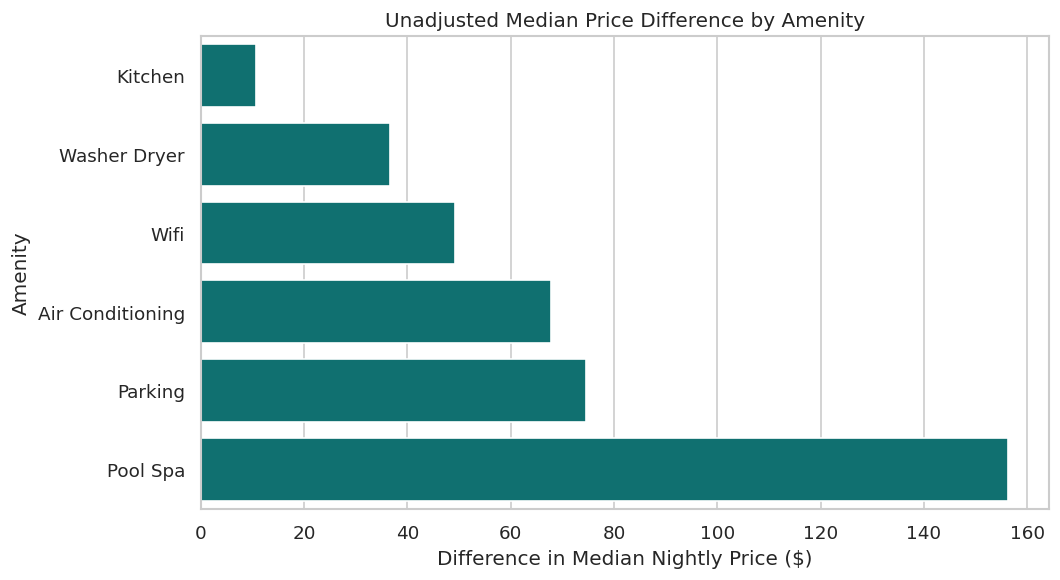

In [ ]:

# Sort amenities by median price difference
difference_plot = amenity_comparison.sort_values(
    "Median Difference",
    ascending=True
)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=difference_plot,
    x="Median Difference",
    y="Amenity",
    color="teal"
)

plt.title("Unadjusted Median Price Difference by Amenity")
plt.xlabel("Difference in Median Nightly Price ($)")
plt.ylabel("Amenity")
plt.tight_layout()
plt.show()


**Unadjusted price comparisons**

Listings with a detected amenity had a higher median nightly price for each of the six amenity groups. Pool/spa had the largest gap, with a median of USD 303.00 when detected and USD 146.63 otherwise. Kitchen had the smallest gap at USD 10.61. The regression below accounts for differences in property, host, and neighborhood characteristics.

## 6.5 Baseline Regression — Property Characteristics

In [ ]:

# Reuse the property-characteristics model from RQ1
rq2_baseline_model = rq1_model

print("Baseline Model: Property Characteristics")
print(f"Observations: {int(rq2_baseline_model.nobs):,}")
print(f"R-squared: {rq2_baseline_model.rsquared:.4f}")
print(
    "Adjusted R-squared:",
    round(rq2_baseline_model.rsquared_adj, 4)
)


Baseline Model: Property Characteristics
Observations: 17,678
R-squared: 0.6549
Adjusted R-squared: 0.6547


## 6.6 Multiple Regression — Property Characteristics and Amenities

We extend the baseline regression by adding the six amenity indicators.

The dependent variable remains the natural logarithm of nightly price (log_price).

The model includes the following predictors:

**Property Characteristics**

* Bedrooms

* Bathrooms

*  Guest capacity

* Room type

**Amenities**

* Wi-Fi

* Parking

* Pool/Spa

* Air conditioning

* Kitchen

* Washer/Dryer

In [ ]:

# Combine the six amenity variables into the formula
amenity_terms = " + ".join(amenity_columns)

# Extend the RQ1 property-characteristics model
rq2_amenity_formula = (
    rq1_formula + " + " + amenity_terms
)

# Fit amenity-adjusted regression
rq2_amenity_model = smf.ols(
    formula=rq2_amenity_formula,
    data=price_data
).fit(cov_type="HC3")

print(rq2_amenity_model.summary())


                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.686
Model:                            OLS   Adj. R-squared:                  0.686
Method:                 Least Squares   F-statistic:                     2716.
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        05:56:51   Log-Likelihood:                -14623.
No. Observations:               17678   AIC:                         2.927e+04
Df Residuals:                   17665   BIC:                         2.937e+04
Df Model:                          12                                         
Covariance Type:                  HC3                                         
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

## 6.7 Full Regression with Additional Controls

In [ ]:

# Add host characteristics to the amenity model
rq2_host_formula = (
    rq2_amenity_formula
    + " + superhost + availability_365"
)

rq2_host_model = smf.ols(
    formula=rq2_host_formula,
    data=price_data
).fit(cov_type="HC3")

print(rq2_host_model.summary())


                            OLS Regression Results                            
Dep. Variable:              log_price   R-squared:                       0.690
Model:                            OLS   Adj. R-squared:                  0.690
Method:                 Least Squares   F-statistic:                     2405.
Date:                Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                        05:56:51   Log-Likelihood:                -14500.
No. Observations:               17678   AIC:                         2.903e+04
Df Residuals:                   17663   BIC:                         2.915e+04
Df Model:                          14                                         
Covariance Type:                  HC3                                         
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept       

### 6.7.2 Add neighborhood fixed effects

In [ ]:
# Add neighborhood controls
rq2_full_formula = (
    rq2_host_formula
    + " + C(neighbourhood_cleansed)"
)
rq2_full_model = smf.ols(
    formula=rq2_full_formula,
    data=price_data
).fit(cov_type="HC3")
assert int(rq2_full_model.nobs) == len(price_data)
print("The neighborhood-adjusted results are reported in the next section.")

The neighborhood-adjusted results are reported in the next section.


## 6.8 Model Comparison and Coefficient Visualization



In [ ]:

# Compare all RQ2 model specifications
rq2_models = {
    "Property Baseline": rq2_baseline_model,
    "Property + Amenities": rq2_amenity_model,
    "Add Host Controls": rq2_host_model,
    "Add Neighborhood": rq2_full_model
}

rq2_model_comparison = pd.DataFrame([
    {
        "Model": name,
        "Observations": int(model.nobs),
        "R-squared": model.rsquared,
        "Adjusted R-squared": model.rsquared_adj
    }
    for name, model in rq2_models.items()
])

display(rq2_model_comparison.round(4))


,Model,Observations,R-squared,Adjusted R-squared
0,Property Baseline,17678,0.6549,0.6547
1,Property + Amenities,17678,0.6857,0.6855
2,Add Host Controls,17678,0.6901,0.6898
3,Add Neighborhood,17678,0.7573,0.7555


In [ ]:
# Extract only the amenity coefficients
rq2_coefficients = pd.DataFrame({
    "Amenity": amenity_columns,
    "Coefficient": rq2_full_model.params[amenity_columns].values,
    "P-value": rq2_full_model.pvalues[amenity_columns].values,
    "CI Lower": rq2_full_model.conf_int().loc[
        amenity_columns, 0
    ].values,
    "CI Upper": rq2_full_model.conf_int().loc[
        amenity_columns, 1
    ].values
})

# Convert log coefficients into percentage differences
rq2_coefficients["Price Difference (%)"] = (
    np.expm1(rq2_coefficients["Coefficient"]) * 100
)

rq2_coefficients_display = rq2_coefficients.round(4)
rq2_coefficients_display["P-value"] = rq2_coefficients["P-value"].map(lambda p: "< 0.001" if p < 0.001 else f"{p:.4f}")
display(rq2_coefficients_display)

,Amenity,Coefficient,P-value,CI Lower,CI Upper,Price Difference (%)
0,wifi,-0.0082,0.8657,-0.1034,0.0870,-0.8180
1,parking,0.0112,0.3699,-0.0133,0.0356,1.1245
2,pool_spa,0.2497,< 0.001,0.2300,0.2694,28.3657
3,air_conditioning,0.1610,< 0.001,0.1397,0.1824,17.4740
4,kitchen,-0.1945,< 0.001,-0.2278,-0.1612,-17.6769
5,washer_dryer,-0.0990,< 0.001,-0.1231,-0.0749,-9.4292


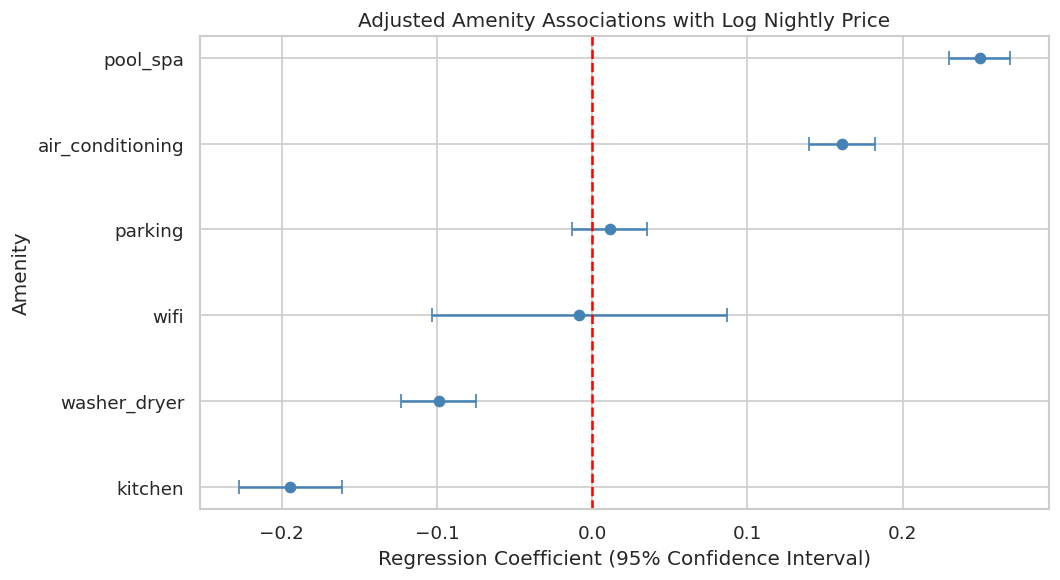

In [ ]:

# Sort the coefficients for visualization
coef_plot = rq2_coefficients.sort_values(
    "Coefficient"
).reset_index(drop=True)

# Calculate confidence interval distances
lower_errors = (
    coef_plot["Coefficient"] - coef_plot["CI Lower"]
)

upper_errors = (
    coef_plot["CI Upper"] - coef_plot["Coefficient"]
)

plt.figure(figsize=(9, 5))

plt.errorbar(
    x=coef_plot["Coefficient"],
    y=coef_plot["Amenity"],
    xerr=[lower_errors, upper_errors],
    fmt="o",
    capsize=4,
    color="steelblue"
)

plt.axvline(
    0,
    color="red",
    linestyle="--"
)

plt.title("Adjusted Amenity Associations with Log Nightly Price")
plt.xlabel("Regression Coefficient (95% Confidence Interval)")
plt.ylabel("Amenity")
plt.tight_layout()
plt.show()


## 6.9 Research Question 2 — Key Findings

Pool/spa had the largest unadjusted median price gap at USD 156.37 per night. Adding all six amenity indicators to the property-only model increased the in-sample R² from 0.655 to 0.686.

In the model that also accounts for Superhost status, availability, and neighborhood, pool/spa and air conditioning were associated with approximately 28.4% and 17.5% higher nightly asking prices, respectively. Kitchen and washer/dryer were associated with approximately 17.7% and 9.4% lower prices. These four associations were statistically significant at the 5% level. The Wi-Fi and parking estimates were statistically inconclusive at that threshold. The full model had an in-sample R² of 0.757.

# 7. Research Question 3 — Host Characteristics and Nightly Prices

**Research Question**: How are host characteristics, particularly Superhost status and availability, associated with nightly Airbnb prices?

This section examines whether Superhost status and annual listing availability are associated with Airbnb nightly prices in the City of Los Angeles.

We first use pivot tables and bar charts to compare nightly prices across Superhost status and availability groups.

Next, we use multiple linear regression to examine these relationships while accounting for property characteristics, amenities, and neighborhood.

The analysis uses the cleaned price_data dataset from Section 4.

## 7.1 Superhost Status and Nightly Prices

We compare average and median nightly prices between Superhost and non-Superhost listings.

In [ ]:
# Compare nightly prices by Superhost status
superhost_pivot = (
    price_data.groupby("superhost")["price"]
    .agg(["count", "mean", "median"])
    .round(2)
)
# Rename group labels
superhost_pivot = superhost_pivot.rename(index={0: "Not Superhost", 1: "Superhost"})
display(superhost_pivot)

,count,mean,median
superhost,,,
Not Superhost,11140,315.62,156.17
Superhost,6538,413.11,232.88


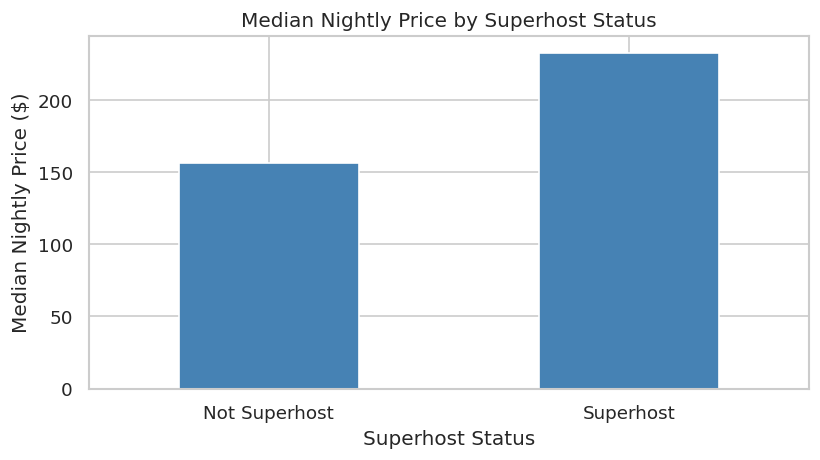

In [ ]:

# Median nightly price by Superhost status
superhost_pivot["median"].plot(
    kind="bar",
    color="steelblue",
    figsize=(7, 4),
    rot=0
)

plt.title("Median Nightly Price by Superhost Status")
plt.xlabel("Superhost Status")
plt.ylabel("Median Nightly Price ($)")
plt.tight_layout()
plt.show()


**Superhost price comparison**

The median nightly price was USD 232.88 for Superhost listings and USD 156.17 for other listings. This comparison does not adjust for listing characteristics.

## 7.2 Availability and Nightly Prices

We examine how nightly prices vary based on the number of days a listing is available over the next 365 days.

In [ ]:

# Group listings by annual availability
availability_groups = pd.cut(
    price_data["availability_365"],
    bins=[-1, 90, 180, 270, 365],
    labels=[
        "0–90 days",
        "91–180 days",
        "181–270 days",
        "271–365 days"
    ]
)

# Compare prices across availability groups
availability_pivot = (
    price_data.groupby(
        availability_groups,
        observed=True
    )["price"]
    .agg(["count", "mean", "median"])
    .round(2)
)

display(availability_pivot)


,count,mean,median
availability_365,,,
0–90 days,2090,326.55,198.00
91–180 days,2398,348.57,192.68
181–270 days,3363,303.70,172.09
271–365 days,9827,374.20,177.00


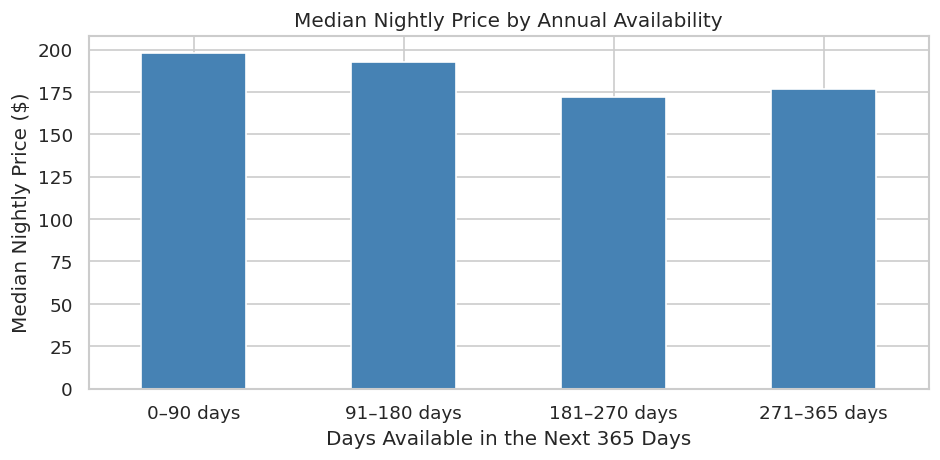

In [ ]:

# Median nightly price by availability group
availability_pivot["median"].plot(
    kind="bar",
    color="steelblue",
    figsize=(8, 4),
    rot=0
)

plt.title("Median Nightly Price by Annual Availability")
plt.xlabel("Days Available in the Next 365 Days")
plt.ylabel("Median Nightly Price ($)")
plt.tight_layout()
plt.show()


**Availability price comparison**

Listings marked available for 0–90 days had the highest median nightly price at USD 198.00. Those available for 181–270 days had the lowest at USD 172.09. Unavailable dates can reflect either bookings or dates blocked by the host.

## 7.3 Multiple Linear Regression

We use multiple linear regression to examine whether Superhost status and availability are associated with nightly prices after accounting for other listing characteristics.

The dependent variable is log_price.

We use the existing adjusted regression model from Research Question 2, which includes property characteristics, all six amenity groups, Superhost status, availability, and neighborhood indicators.

We focus on the Superhost and availability coefficients to answer Research Question 3.

In [ ]:
# Express availability in a 30-day increment using the fitted daily coefficient.
host_vars = ["superhost", "availability_365"]
increments = np.array([1, 30])
rq3_results = pd.DataFrame({
    "Comparison": ["Superhost vs. other host", "30 additional available days"],
    "Price difference (%)": 100 * np.expm1(rq2_full_model.params[host_vars].to_numpy() * increments),
    "P-value": rq2_full_model.pvalues[host_vars].to_numpy(),
})
rq3_results_display = rq3_results.round(4)
rq3_results_display["P-value"] = rq3_results["P-value"].map(lambda p: "< 0.001" if p < 0.001 else f"{p:.4f}")
display(rq3_results_display.reset_index(drop=True))
print(f"Model R-squared: {rq2_full_model.rsquared:.4f}")

,Comparison,Price difference (%),P-value
0,Superhost vs. other host,9.0117,< 0.001
1,30 additional available days,-0.3718,< 0.001


Model R-squared: 0.7573


**Regression results**

In the neighborhood-adjusted model, Superhost listings were associated with 9.0% higher nightly asking prices (p < 0.001) after holding the other included variables constant. An additional 30 days marked available was associated with about 0.37% lower prices (p < 0.001). The full model explains 75.7% of the in-sample variation in log nightly asking prices.

## 7.4 Research Question 3 — Key Findings

Superhost listings had higher median nightly asking prices, and the association remained positive after adjusting for property characteristics, amenities, availability, and neighborhood. More days marked available had a small negative adjusted association with nightly price. A listing’s available days can reflect both bookings and calendar decisions by the host.

# 8. Research Question 4 — Listing Characteristics and Guest Ratings

**Research Question**: Are listing characteristics, amenities, and nightly prices associated with guest ratings?

This section examines the relationships between Airbnb guest ratings, nightly prices, property characteristics, and amenities in the City of Los Angeles.

We first explore the distribution of guest ratings and their relationship with nightly prices. Next, we use multiple linear regression to examine which listing characteristics are associated with guest ratings.

The analysis uses ratings_data, which contains listings with complete information for the selected variables.

## 8.1 Guest Ratings Overview

Among the 12,133 listings in the ratings sample, observed overall ratings ranged from 1 to 5 stars. The median was 4.93, and the upper quartile was 5.00.

,review_scores_rating
count,12133.00
mean,4.78
std,0.45
min,1.00
25%,4.76
50%,4.93
75%,5.00
max,5.00


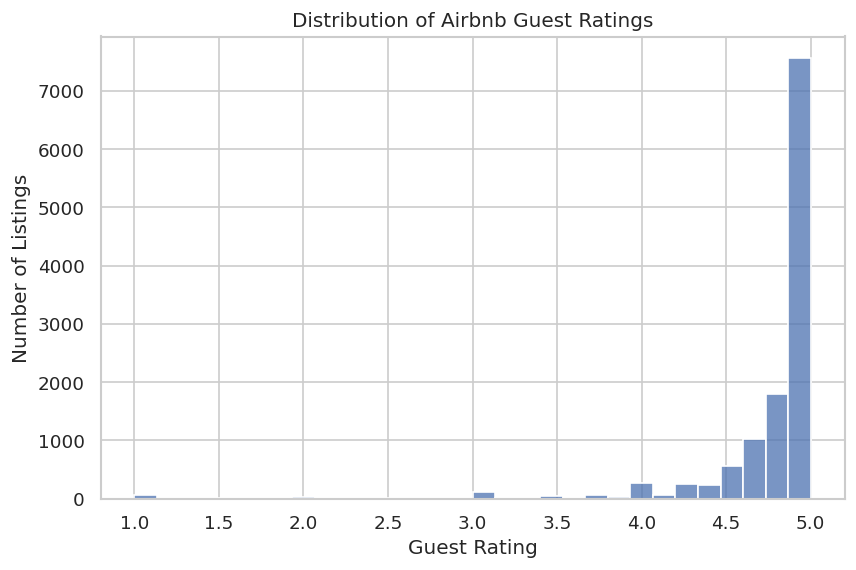

In [ ]:

# Summary statistics for guest ratings
display(
    ratings_data["review_scores_rating"]
    .describe()
    .round(2)
)

# Distribution of guest ratings
sns.histplot(
    data=ratings_data,
    x="review_scores_rating",
    bins=30
)

plt.title("Distribution of Airbnb Guest Ratings")
plt.xlabel("Guest Rating")
plt.ylabel("Number of Listings")
plt.show()


## 8.2 Nightly Prices and Guest Ratings

We examine whether more expensive Airbnb listings tend to receive higher guest ratings.

We use a scatterplot to visualize the relationship and Spearman correlation to measure the strength and direction of the association.

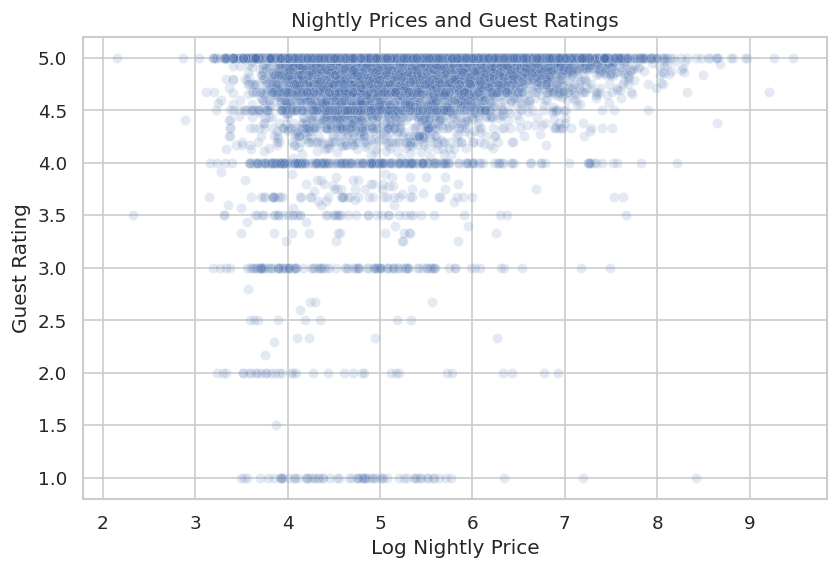

,log_price,review_scores_rating
log_price,1.000,0.085
review_scores_rating,0.085,1.000


In [ ]:

# Scatterplot: Nightly price and guest ratings
sns.scatterplot(
    data=ratings_data,
    x="log_price",
    y="review_scores_rating",
    alpha=0.15
)

plt.title("Nightly Prices and Guest Ratings")
plt.xlabel("Log Nightly Price")
plt.ylabel("Guest Rating")
plt.show()

# Spearman correlation
correlation = ratings_data[
    ["log_price", "review_scores_rating"]
].corr(method="spearman")

display(correlation.round(3))


## 8.3 Multiple Linear Regression

We use multiple linear regression to examine which listing characteristics are associated with overall guest ratings.

The dependent variable is review_scores_rating.

The independent variables include log nightly price, bedrooms, bathrooms, guest capacity, room type, Superhost status, all six amenity categories, and neighborhood indicators.

This model helps us examine the association between each variable and guest ratings while accounting for the other included listing characteristics.

In [ ]:

# Use the same six amenity groups as RQ2
amenity_terms = " + ".join(amenity_columns)

# Guest ratings regression with neighborhood controls

rating_formula = (
    "review_scores_rating ~ log_price"
    " + bedrooms + bathrooms_num"
    " + accommodates + C(room_type)"
    " + superhost + " + amenity_terms
    + " + C(neighbourhood_cleansed)"
)

rating_model = smf.ols(
    formula=rating_formula,
    data=ratings_data
).fit(cov_type="HC3")


In [ ]:
# Show only selected regression results
rating_vars = [
    "log_price",
    "bedrooms",
    "bathrooms_num",
    "accommodates",
    "superhost"
] + amenity_columns

rating_results = pd.DataFrame({
    "Coefficient": rating_model.params[rating_vars],
    "P-value": rating_model.pvalues[rating_vars]
})

rating_results_display = rating_results.round(4)
rating_results_display["P-value"] = rating_results["P-value"].map(lambda p: "< 0.001" if p < 0.001 else f"{p:.4f}")
display(rating_results_display)
print(f"Observations: {int(rating_model.nobs):,}")
print(f"In-sample R-squared: {rating_model.rsquared:.4f}")
print(f"Rating-point difference for twice the nightly price: {rating_model.params['log_price'] * np.log(2):.3f}")

,Coefficient,P-value
log_price,0.0872,< 0.001
bedrooms,0.0152,0.0205
bathrooms_num,-0.0010,0.8020
accommodates,-0.0230,< 0.001
superhost,0.1374,< 0.001
wifi,0.0840,0.3808
parking,0.0371,0.0582
pool_spa,-0.0090,0.3501
air_conditioning,0.0105,0.3109
kitchen,-0.0147,0.2735


Observations: 12,133
In-sample R-squared: 0.0943
Rating-point difference for twice the nightly price: 0.060


## 8.4 Research Question 4 — Key Findings

The Spearman correlation between nightly price and guest rating was 0.085, indicating a weak positive association in the ratings sample. In the adjusted regression, doubling nightly price was associated with approximately 0.060 additional rating points, and Superhost status was associated with approximately 0.137 additional points, holding other model variables constant.

The model explains about 9.4% of observed variation in ratings. Ratings clustered near five stars, and the analysis represents listings with a recorded rating.

# 9. Overall Results and Key Insights

| Research question | Main finding |
|---|---|
| RQ1 · Property characteristics | Bedrooms, bathrooms, guest capacity, and room type were associated with nightly asking prices. Adding neighborhood indicators increased in-sample R² from 0.655 to 0.737. |
| Neighborhood · RQ1 follow-up | Neighborhood indicators increased in-sample R² by 8.2 percentage points in the property model. The neighborhood chart compares asking-price medians among the 10 most-represented neighborhoods. |
| RQ2 · Amenities | Pool/spa and air conditioning had positive adjusted associations with nightly asking prices. Kitchen and washer/dryer had negative adjusted associations. |
| RQ3 · Superhost status and availability | Superhost listings were associated with 9.0% higher nightly asking prices. Thirty additional available days were associated with 0.37% lower prices after adjustment. |
| RQ4 · Guest ratings | Nightly price had a weak positive correlation with overall ratings. The adjusted model explained 9.4% of the observed variation in ratings. |

# 10. Limitations and Conclusion

## 10.1 Limitations

The dataset is a snapshot of advertised listings and nightly asking prices. The prices guests paid may differ. Calendar availability can reflect both bookings and dates blocked by hosts.

The models use complete cases. Listings excluded because of missing prices, ratings, or predictors may differ from the listings analyzed. Ratings cluster near five stars and represent listings with recorded ratings. Unmeasured factors, such as property condition, seasonality, and guest expectations, may influence the observed relationships. Several listings can share the same host. The models use HC3 standard errors, which address unequal error variance and leave within-host dependence unmodeled. The reported R² values measure fit on the data used to estimate each model.

## 10.2 Conclusion

In the City of Los Angeles sample, property characteristics, neighborhood, selected amenities, and Superhost status were associated with nightly asking prices. The ratings model explained a much smaller share of variation in its outcome. These observational results describe associations among the listings analyzed.